Classical Map

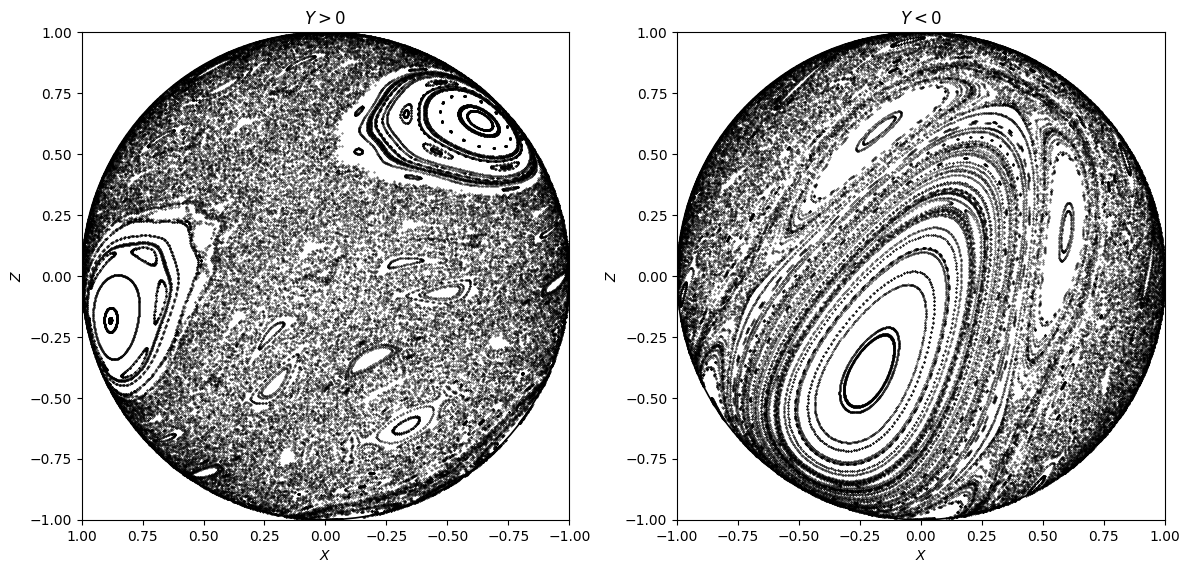

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# ==========================================================
# PARAMETERS
# ==========================================================

p = 0.99
k = 2.0
a = 0.4576

dt = 0.05
kick_steps = 20
n_kicks = 500
n_traj = 300


# ==========================================================
# CLASSICAL KICKED-TOP MAP
# ==========================================================

def kicked_top_map(x, y, z):
    """
    Applies one complete classical kick.

    The nonlinear evolution is integrated using RK4,
    followed by a rotation about the y-axis.
    """

    # ------------------------------------------------------
    # Nonlinear evolution
    #
    # dX/dtau = -a Y
    # dY/dtau = (a - k Z) X
    # dZ/dtau = k X Y
    # ------------------------------------------------------

    for _ in range(kick_steps):

        # ---------- k1 ----------
        dx1 = -a * y
        dy1 = (a - k * z) * x
        dz1 = k * x * y

        # ---------- k2 ----------
        x2 = x + 0.5 * dt * dx1
        y2 = y + 0.5 * dt * dy1
        z2 = z + 0.5 * dt * dz1

        dx2 = -a * y2
        dy2 = (a - k * z2) * x2
        dz2 = k * x2 * y2

        # ---------- k3 ----------
        x3 = x + 0.5 * dt * dx2
        y3 = y + 0.5 * dt * dy2
        z3 = z + 0.5 * dt * dz2

        dx3 = -a * y3
        dy3 = (a - k * z3) * x3
        dz3 = k * x3 * y3

        # ---------- k4 ----------
        x4 = x + dt * dx3
        y4 = y + dt * dy3
        z4 = z + dt * dz3

        dx4 = -a * y4
        dy4 = (a - k * z4) * x4
        dz4 = k * x4 * y4

        # ---------- RK4 update ----------
        x += dt * (dx1 + 2*dx2 + 2*dx3 + dx4) / 6
        y += dt * (dy1 + 2*dy2 + 2*dy3 + dy4) / 6
        z += dt * (dz1 + 2*dz2 + 2*dz3 + dz4) / 6

    # ------------------------------------------------------
    # Normalize once after nonlinear evolution
    # This compensates for small numerical RK4 errors.
    # ------------------------------------------------------

    norm = np.sqrt(x**2 + y**2 + z**2)

    x /= norm
    y /= norm
    z /= norm

    # ------------------------------------------------------
    # Linear rotation about the y-axis
    #
    # X' = X cos(p) + Z sin(p)
    # Y' = Y
    # Z' = -X sin(p) + Z cos(p)
    # ------------------------------------------------------

    x_new = x * np.cos(p) + z * np.sin(p)
    y_new = y
    z_new = -x * np.sin(p) + z * np.cos(p)

    return x_new, y_new, z_new


# ==========================================================
# INITIAL CONDITIONS
# ==========================================================

np.random.seed(42)

# Generate random points in 3D
states = np.random.normal(size=(n_traj, 3))

# Normalize them so that every point lies on the unit sphere
states /= np.linalg.norm(states, axis=1)[:, None]


for i in states :
    i[1] = -i[1]


# ==========================================================
# PLOT
# ==========================================================

fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 6)
)


# ==========================================================
# EVOLVE ALL TRAJECTORIES
# ==========================================================

for i in range(n_traj):

    # Initial point
    x, y, z = states[i]

    # Lists for the two hemispheres
    positive_y_x = []
    positive_y_z = []

    negative_y_x = []
    negative_y_z = []

    # ------------------------------------------------------
    # Evolution
    # ------------------------------------------------------

    for _ in range(n_kicks):

        x, y, z = kicked_top_map(x, y, z)

        # Separate according to the sign of Y
        if y > 0:
            positive_y_x.append(x)
            positive_y_z.append(z)

        else:
            negative_y_x.append(x)
            negative_y_z.append(z)

    # ------------------------------------------------------
    # Y > 0
    # ------------------------------------------------------

    ax[0].scatter(
        positive_y_x,
        positive_y_z,
        s=0.1,
        color="black"
    )

    # ------------------------------------------------------
    # Y < 0
    # ------------------------------------------------------

    ax[1].scatter(
        negative_y_x,
        negative_y_z,
        s=0.1,
        color="black"
    )


# ==========================================================
# FORMATTING
# ==========================================================

titles = [
    r"$Y>0$",
    r"$Y<0$"
]

for i in range(2):

    # Unit circle
    circle = plt.Circle(
        (0, 0),
        1,
        edgecolor="black",
        facecolor="none",
        lw=1.2
    )

    ax[i].add_artist(circle)

    # Axis limits
    ax[i].set_xlim(-1, 1)
    ax[i].set_ylim(-1, 1)

    # Equal aspect ratio
    ax[i].set_aspect("equal")

    # Labels
    ax[i].set_xlabel(r"$X$")
    ax[i].set_ylabel(r"$Z$")

    # Titles
    ax[i].set_title(titles[i])


# ==========================================================
# VIEWING CONVENTION
# ==========================================================

# Reverse X-axis for the Y > 0 projection
ax[0].invert_xaxis()


# ==========================================================
# FINAL PLOT
# ==========================================================

plt.tight_layout()
plt.show()

Classical evolution of 3 initial condition

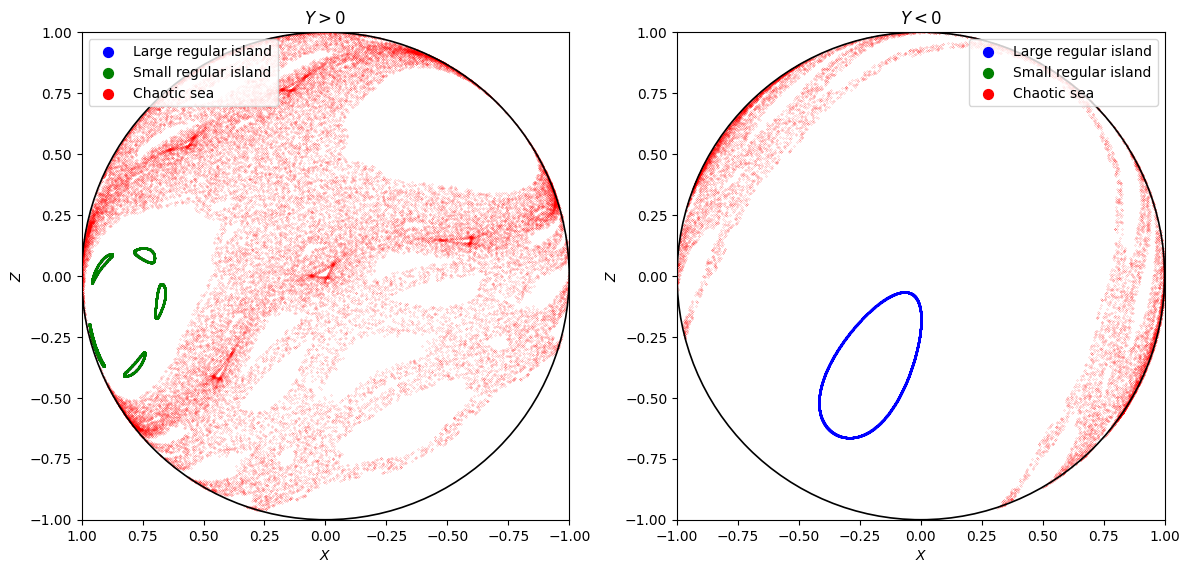

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# PARAMETERS
# ==========================================================
k = 2.0
p = 0.99
a = 0.4576

n_kicks = 50000

# RK4 integration parameters
dt = 0.05
kick_steps = 20

# ==========================================================
# CLASSICAL KICKED-TOP MAP
# ==========================================================

def kicked_top_map(x, y, z):
    """
    Applies one complete classical kick.

    The nonlinear evolution is integrated using RK4,
    followed by a rotation about the y-axis.
    """

    # ------------------------------------------------------
    # Nonlinear evolution
    #
    # dX/dtau = -a Y
    # dY/dtau = (a - k Z) X
    # dZ/dtau = k X Y
    # ------------------------------------------------------

    for _ in range(kick_steps):

        # ---------- k1 ----------
        dx1 = -a * y
        dy1 = (a - k * z) * x
        dz1 = k * x * y

        # ---------- k2 ----------
        x2 = x + 0.5 * dt * dx1
        y2 = y + 0.5 * dt * dy1
        z2 = z + 0.5 * dt * dz1

        dx2 = -a * y2
        dy2 = (a - k * z2) * x2
        dz2 = k * x2 * y2

        # ---------- k3 ----------
        x3 = x + 0.5 * dt * dx2
        y3 = y + 0.5 * dt * dy2
        z3 = z + 0.5 * dt * dz2

        dx3 = -a * y3
        dy3 = (a - k * z3) * x3
        dz3 = k * x3 * y3

        # ---------- k4 ----------
        x4 = x + dt * dx3
        y4 = y + dt * dy3
        z4 = z + dt * dz3

        dx4 = -a * y4
        dy4 = (a - k * z4) * x4
        dz4 = k * x4 * y4

        # ---------- RK4 update ----------
        x += dt * (dx1 + 2*dx2 + 2*dx3 + dx4) / 6
        y += dt * (dy1 + 2*dy2 + 2*dy3 + dy4) / 6
        z += dt * (dz1 + 2*dz2 + 2*dz3 + dz4) / 6

    # ------------------------------------------------------
    # Normalize once after nonlinear evolution
    # This compensates for small numerical RK4 errors.
    # ------------------------------------------------------

    norm = np.sqrt(x**2 + y**2 + z**2)

    x /= norm
    y /= norm
    z /= norm

    # ------------------------------------------------------
    # Linear rotation about the y-axis
    #
    # X' = X cos(p) + Z sin(p)
    # Y' = Y
    # Z' = -X sin(p) + Z cos(p)
    # ------------------------------------------------------

    x_new = x * np.cos(p) + z * np.sin(p)
    y_new = y
    z_new = -x * np.sin(p) + z * np.cos(p)

    return x_new, y_new, z_new


# ==========================================================
# Initial conditions
# ==========================================================
initial_conditions = [
    {
        "label": "Large regular island",
        "point": np.array([0.00, -0.99, -0.16]),
        "color": "blue"
    },
    {
        "label": "Small regular island",
        "point": np.array([0.70, 0.70, -0.16]),
        "color": "green"
    },
    {
        "label": "Chaotic sea",
        "point": np.array([-0.94, 0.31, -0.16]),
        "color": "red"
    }
]

# Normalize to the unit sphere
for ic in initial_conditions:
    ic["point"] = ic["point"] / np.linalg.norm(ic["point"])

# ==========================================================
# Plot
# ==========================================================
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

for ic in initial_conditions:

    x, y, z = ic["point"]

    upper_x = []
    upper_z = []

    lower_x = []
    lower_z = []

    for _ in range(n_kicks):

        x, y, z = kicked_top_map(x, y, z)

        if y > 0:
            upper_x.append(x)
            upper_z.append(z)
        else:
            lower_x.append(x)
            lower_z.append(z)

    ax[0].scatter(
        upper_x,
        upper_z,
        s=0.01,
        color=ic["color"],
        label=ic["label"]
    )

    ax[1].scatter(
        lower_x,
        lower_z,
        s=0.01,
        color=ic["color"],
        label=ic["label"]
    )

# ==========================================================
# Formatting
# ==========================================================

titles = [r"$Y>0$", r"$Y<0$"]

for i in range(2):

    circle = plt.Circle(
        (0, 0),
        1,
        edgecolor='black',
        facecolor='none',
        lw=1.2
    )

    ax[i].add_artist(circle)

    ax[i].set_xlim(-1, 1)
    ax[i].set_ylim(-1, 1)
    ax[i].set_aspect('equal')

    ax[i].set_xlabel(r"$X$")
    ax[i].set_ylabel(r"$Z$")
    ax[i].set_title(titles[i])

# Match your previous convention
ax[0].invert_xaxis()

# Legend
for i in range(2):
    if i == 0:
        leg = ax[i].legend(loc="upper left")
    if i == 1:
        leg = ax[i].legend(loc="upper right")

    # Loop through the legend handles and manually increase their size
    for handle in leg.legend_handles:
        handle.set_sizes([50.0])  # 50.0 is a good visible size for legend markers

plt.tight_layout()
plt.show()

Eigenvalues and Eigenvectors

=== Eigenstate Overlaps ===
Overlap with initial state: eigenphase : -2.7835 overlap : 0.81
Overlap with initial state: eigenphase : -2.4539 overlap : 0.00
Overlap with initial state: eigenphase : -2.1985 overlap : 0.00
Overlap with initial state: eigenphase : -1.0176 overlap : 0.13
Overlap with initial state: eigenphase : 0.5146 overlap : 0.03
Overlap with initial state: eigenphase : 1.8257 overlap : 0.03
Overlap with initial state: eigenphase : 2.8802 overlap : 0.00

Calculating Husimi distributions for all eigenstates...


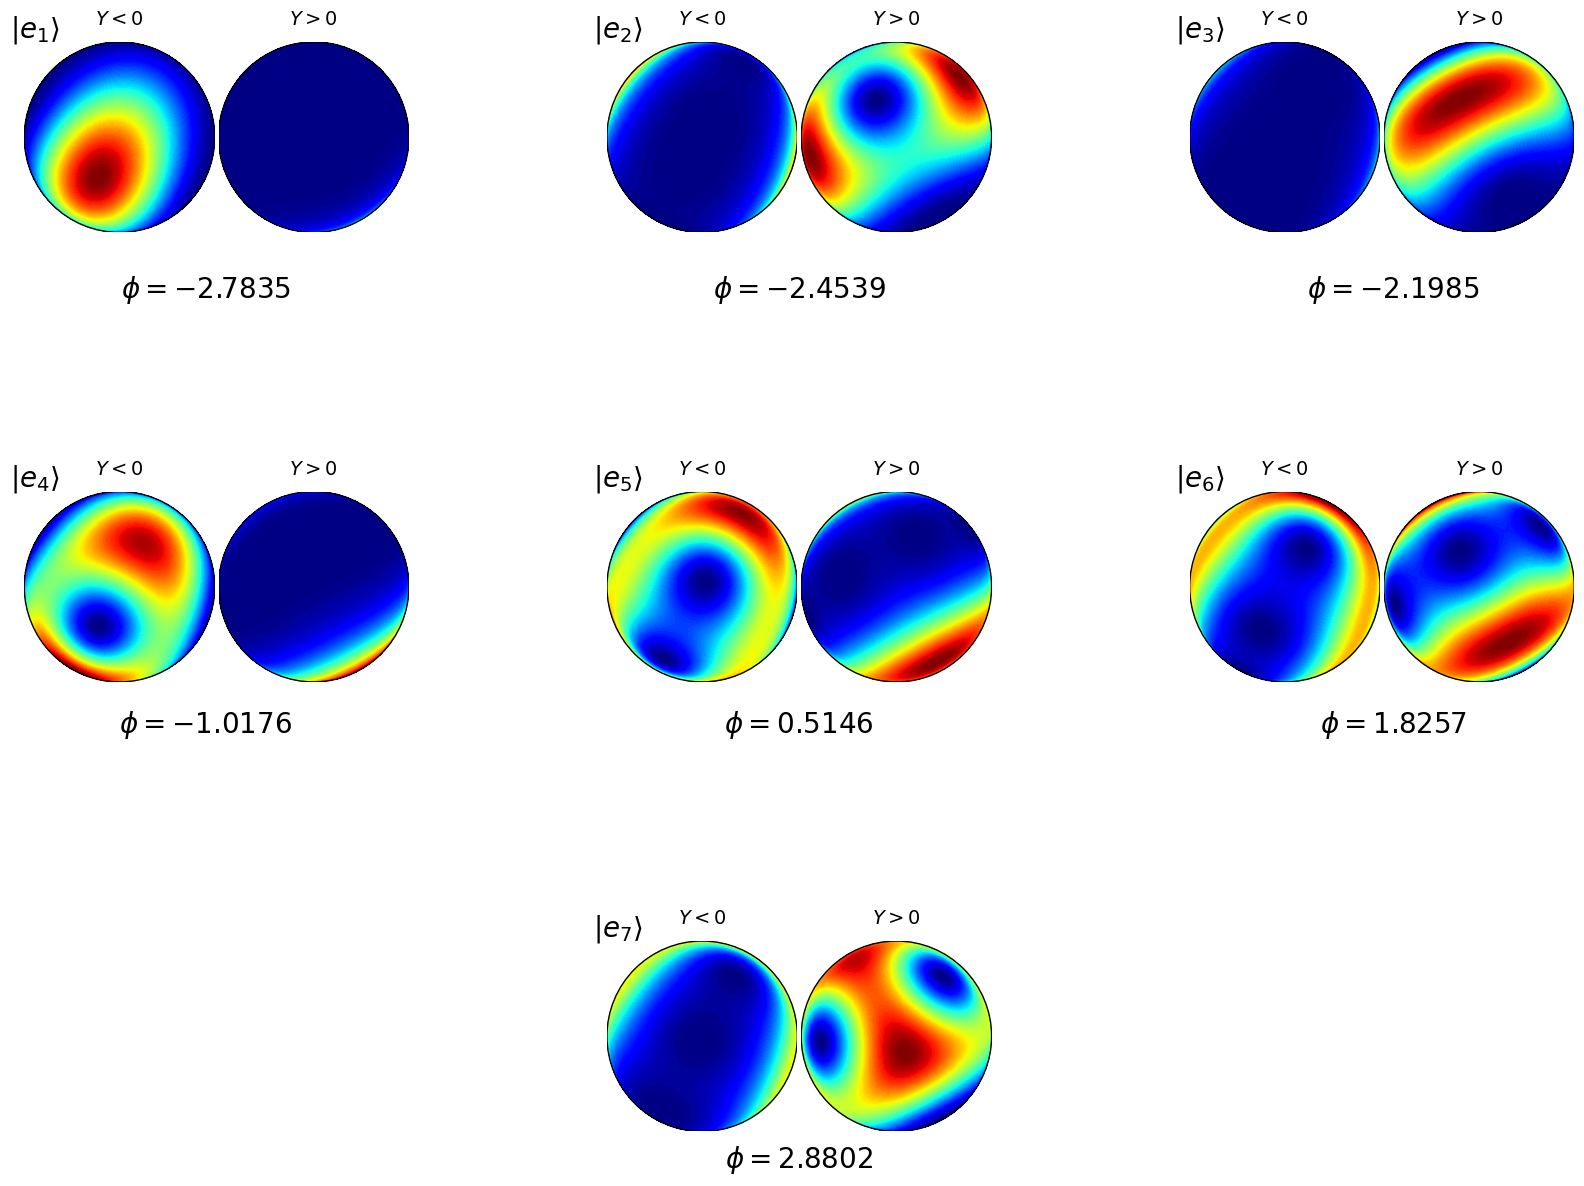

In [4]:
import numpy as np
from scipy.linalg import expm
import scipy.special as special
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. UNIFIED SYSTEM PARAMETERS ---
j = 3.0
dim = int(2 * j + 1)

# Using consistent physics parameters for both methods
a_param = 0.4576
p_param = 0.99
kappa_param = 2.0
tau_param = 1.0
sigma_param = 0.001

# --- 2. GENERATE SPIN MATRICES ONCE ---
m = np.arange(j, -j-1, -1)
Jz = np.diag(m).astype(complex)

Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim):
    for k in range(dim):
        if k == i+1:
            Jp[i, k] = np.sqrt(j*(j+1) - m[k]*(m[k]+1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx





def gaussian_pulse(t, tau_val, sigma_val):
    # Center the pulse 6*sigma before tau so the full integral falls exactly inside [0, tau]
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, Jx2, Jy_mat, Jz_mat, a, p, kappa, j_spin, tau, sigma):
    N = Jx2.shape[0]
    U = U_flat.reshape((N, N))

    f_t = gaussian_pulse(t, tau, sigma)

    # Time-dependent Hamiltonian
    H_t = p * f_t * Jy_mat + (kappa / (2.0 * j_spin * tau)) * Jx2 + (a / tau) * Jz_mat
    dU_dt = -1j * (H_t @ U)

    return dU_dt.flatten()

def compute_floquet_ode():
    U0 = np.eye(dim, dtype=complex).flatten()

    # CRITICAL FIX: max_step=sigma_param ensures the solver doesn't skip the kick
    sol = solve_ivp(
        fun=ode_rhs,
        t_span=(0.0, tau_param),
        y0=U0,
        args=(Jx_sq, Jy, Jz, a_param, p_param, kappa_param, j, tau_param, sigma_param),
        method='RK45',
        rtol=1e-10,
        atol=1e-12,
        max_step=sigma_param
    )

    return sol.y[:, -1].reshape((dim, dim))

U =  compute_floquet_ode()

# --- 2. EIGENDECOMPOSITION & PHASE SORTING ---
eigenvalues, P = np.linalg.eig(U)

# Re-sort BOTH using the same indices to preserve pairing
sort_indices = np.argsort(-np.angle(eigenvalues))
eigenvalues = eigenvalues[sort_indices]
P = P[:, sort_indices]

eigenphases = -np.angle(eigenvalues)

# --- 3. HUSIMI MATH FUNCTIONS ---
def spin_coherent_state(theta, phi):
    k_vals = np.arange(0, dim)
    comb_coeffs = np.sqrt(special.comb(int(2 * j), k_vals))
    cos_val = np.cos(theta / 2)
    sin_val = np.sin(theta / 2)
    # ✅ Changing -1j to +1j aligns <Jy> with +sin(theta)sin(phi)
    coeffs = comb_coeffs * (sin_val ** k_vals) * (cos_val ** (int(2 * j) - k_vals)) * np.exp(1j * k_vals * phi)
    return coeffs.reshape(-1, 1)

def Husimi_function(state, theta, phi):
    coherent_state = spin_coherent_state(theta, phi)
    return np.abs(np.vdot(coherent_state.flatten(), state.flatten()))**2

vec = np.array([0, -0.99, -0.16])
Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)

psi0 = spin_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

print("=== Eigenstate Overlaps ===")
for i in range(len(P)):
    overlap = np.abs(np.vdot(psi0.flatten(), P[:, i].flatten()))**2
    print(f"Overlap with initial state: eigenphase : {eigenphases[i]:.4f} overlap : {overlap:.2f}")

# --- 4. 2D & 3D MESHGRID GENERATION ---
phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)
Phi, Theta = np.meshgrid(phi, theta)

# Map angles to Cartesian coordinates on the unit sphere
X = np.sin(Theta) * np.cos(Phi)
Y = np.sin(Theta) * np.sin(Phi)
Z = np.cos(Theta)

# --- 5. CALCULATE HUSIMI FOR EIGENSTATES ---
husimi_store = []

print("\nCalculating Husimi distributions for all eigenstates...")
for idx in range(dim):
    psi = P[:, idx]  # Extract column eigenvector

    Husimi_vals = np.zeros((len(theta), len(phi)))
    for it, th in enumerate(theta):
        for ip, ph in enumerate(phi):
            Husimi_vals[it, ip] = Husimi_function(psi, th, ph)

    husimi_store.append(Husimi_vals)

# ==========================================================
# Plot all eigenstates in one figure (paper style)
# ==========================================================

levels = np.linspace(0, 1, 100)

# Increased figsize significantly (height from 8 to 16) to make the plots bigger
fig = plt.figure(figsize=(20, 16))

for idx, Hraw in enumerate(husimi_store):

    H = (Hraw-Hraw.min())/(Hraw.max()-Hraw.min())

    H_pos = np.ma.masked_where(Y<0,H)
    H_neg = np.ma.masked_where(Y>0,H)

    # -------- Layout Logic (3 rows: 3-3-1) --------
    # Using an 8-column grid:
    # Col 0 (slots 0,1) | Col 1 (slots 3,4) | Col 2 (slots 6,7)
    # The empty slots (2, 5) act as spacing between the hemisphere pairs
    if idx < 3:
        row = 0
        col = idx
    elif idx < 6:
        row = 1
        col = idx - 3
    else:
        row = 2
        col = 1  # Centered in the middle column

    # Left hemisphere
    ax1 = plt.subplot2grid((3, 8), (row, 3*col))

    cont = ax1.contourf(
        X,
        Z,
        H_neg,
        levels=levels,
        cmap='jet'
    )

    ax1.add_patch(
        plt.Circle(
            (0,0),
            1,
            fill=False,
            color='black',
            lw=1
        )
    )

    ax1.set_aspect('equal')
    ax1.set_xlim(-1,1)
    ax1.set_ylim(-1,1)
    ax1.axis("off")

    ax1.text(
        -1.15,
        1.05,
        rf"$|e_{{{idx+1}}}\rangle$",
        fontsize=20
    )

    ax1.text(
        0,
        1.18,
        r"$Y<0$",
        ha="center",
        fontsize=14
    )

    # Right hemisphere
    ax2 = plt.subplot2grid((3, 8), (row, 3*col+1))

    cont = ax2.contourf(
        X,
        Z,
        H_pos,
        levels=levels,
        cmap='jet'
    )

    ax2.add_patch(
        plt.Circle(
            (0,0),
            1,
            fill=False,
            color='black',
            lw=1
        )
    )

    ax2.set_aspect('equal')
    ax2.set_xlim(-1,1)
    ax2.set_ylim(-1,1)

    ax2.invert_xaxis()
    ax2.axis("off")

    ax2.text(
        0,
        1.18,
        r"$Y>0$",
        ha="center",
        fontsize=14
    )

    # ----- Eigenphase below the pair -----
    pos1 = ax1.get_position()
    pos2 = ax2.get_position()

    x_center = (pos1.x0 + pos2.x1) / 2
    y_bottom = min(pos1.y0, pos2.y0)

    fig.text(
        x_center,
        y_bottom - 0.025, # Adjusted offset to fit larger plots
        rf"$\phi = {eigenphases[idx]:.4f}$",
        ha="center",
        va="top",
        fontsize=20
    )

# Increased hspace so the rows don't overlap with the text
plt.subplots_adjust(
    wspace=0.02,
    hspace=0.35
)

plt.show()

Overlap

In [5]:
import numpy as np
from scipy.linalg import expm
import scipy.special as special
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. UNIFIED SYSTEM PARAMETERS ---
j = 3.0
dim = int(2 * j + 1)

# Using consistent physics parameters for both methods
a_param = 0.4576
p_param = 0.99
kappa_param = 2.0
tau_param = 1.0
sigma_param = 0.001

# --- 2. GENERATE SPIN MATRICES ONCE ---
m = np.arange(j, -j-1, -1)
Jz = np.diag(m).astype(complex)

Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim):
    for k in range(dim):
        if k == i+1:
            Jp[i, k] = np.sqrt(j*(j+1) - m[k]*(m[k]+1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx





def gaussian_pulse(t, tau_val, sigma_val):
    # Center the pulse 6*sigma before tau so the full integral falls exactly inside [0, tau]
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, Jx2, Jy_mat, Jz_mat, a, p, kappa, j_spin, tau, sigma):
    N = Jx2.shape[0]
    U = U_flat.reshape((N, N))

    f_t = gaussian_pulse(t, tau, sigma)

    # Time-dependent Hamiltonian
    H_t = p * f_t * Jy_mat + (kappa / (2.0 * j_spin * tau)) * Jx2 + (a / tau) * Jz_mat
    dU_dt = -1j * (H_t @ U)

    return dU_dt.flatten()

def compute_floquet_ode():
    U0 = np.eye(dim, dtype=complex).flatten()

    # CRITICAL FIX: max_step=sigma_param ensures the solver doesn't skip the kick
    sol = solve_ivp(
        fun=ode_rhs,
        t_span=(0.0, tau_param),
        y0=U0,
        args=(Jx_sq, Jy, Jz, a_param, p_param, kappa_param, j, tau_param, sigma_param),
        method='RK45',
        rtol=1e-10,
        atol=1e-12,
        max_step=sigma_param
    )

    return sol.y[:, -1].reshape((dim, dim))

U =  compute_floquet_ode()

# --- 2. EIGENDECOMPOSITION & PHASE SORTING ---
# 1. Get raw eigenvalues and eigenvectors
eigenvalues, P = np.linalg.eig(U)

# 2. Get the sorting indices based on eigenphase angle
sort_indices = np.argsort(-np.angle(eigenvalues))

# 3. Re-sort BOTH using the same indices to preserve pairing!
eigenvalues = eigenvalues[sort_indices]
P = P[:, sort_indices]

# 4. Now calculate eigenphases from the sorted eigenvalues
eigenphases = -np.angle(eigenvalues)

# --- 3. HUSIMI MATH FUNCTIONS ---
# def spin_coherent_state(theta, phi):
#     k_vals = np.arange(0, dim)
#     comb_coeffs = np.sqrt(special.comb(int(2 * j), k_vals))
#     cos_val = np.cos(theta / 2)
#     sin_val = np.sin(theta / 2)
#     coeffs = comb_coeffs * (sin_val ** k_vals) * (cos_val ** (int(2 * j) - k_vals)) * np.exp(-1j * k_vals * phi)
#     return coeffs.reshape(-1, 1)



# def spin_coherent_state(theta, phi):
#     state = np.full((dim, 1), 1, dtype=complex)

#     z = np.tan(theta/2) * np.exp(1j * phi)

#     for m in range(j, -j-1, -1):
#         coeff = (np.sqrt(special.factorial(int(2*j)) / (special.factorial(int(j+m)) * special.factorial(int(j-m)))))* (z**(j-m))
#         state[int(j-m)] = coeff

#     return state * (1+np.abs(z)**2)**(-j)

def spin_coherent_state(a,b,c):
    vec = np.array([a, b,c])
    Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)
    theta = np.arccos(Jz0)
    phi = np.arctan2(Jy0, Jx0)

    state = np.full((dim, 1), 0, dtype=complex)
    state[0] = 1
    R = expm(-1j * phi * Jz) @ expm(-1j * theta * Jy)

    return R @ state

def Husimi_function(state, theta, phi):
    coherent_state = spin_coherent_state(theta, phi)
    return np.abs(np.vdot(coherent_state.flatten(), state.flatten()))**2

print("\n Island Pair \n")

psi0 = spin_coherent_state(0.70,0.70,-0.16)

for i in range(len(P)):
    # ✅ CORRECT: P[:, i] extracts the i-th COLUMN eigenvector
    overlap = np.abs(np.vdot(psi0.flatten(), P[:, i].flatten()))**2
    print(f"Overlap with initial state: eigenphase : {eigenphases[i]:.4f} overlap : {overlap:.2f}")

print("\n large island \n")

psi0 = spin_coherent_state(0,-0.99,-0.16)

for i in range(len(P)):
    # ✅ CORRECT: P[:, i] extracts the i-th COLUMN eigenvector
    overlap = np.abs(np.vdot(psi0.flatten(), P[:, i].flatten()))**2
    print(f"Overlap with initial state: eigenphase : {eigenphases[i]:.4f} overlap : {overlap:.2f}")

print('\n chaotic sea \n')

psi0 = spin_coherent_state(-0.94,0.31,-0.16)

for i in range(len(P)):
    # ✅ CORRECT: P[:, i] extracts the i-th COLUMN eigenvector
    overlap = np.abs(np.vdot(psi0.flatten(), P[:, i].flatten()))**2
    print(f"Overlap with initial state: eigenphase : {eigenphases[i]:.4f} overlap : {overlap:.2f}")




 Island Pair 

Overlap with initial state: eigenphase : -2.7835 overlap : 0.00
Overlap with initial state: eigenphase : -2.4539 overlap : 0.39
Overlap with initial state: eigenphase : -2.1985 overlap : 0.53
Overlap with initial state: eigenphase : -1.0176 overlap : 0.00
Overlap with initial state: eigenphase : 0.5146 overlap : 0.01
Overlap with initial state: eigenphase : 1.8257 overlap : 0.04
Overlap with initial state: eigenphase : 2.8802 overlap : 0.03

 large island 

Overlap with initial state: eigenphase : -2.7835 overlap : 0.81
Overlap with initial state: eigenphase : -2.4539 overlap : 0.00
Overlap with initial state: eigenphase : -2.1985 overlap : 0.00
Overlap with initial state: eigenphase : -1.0176 overlap : 0.13
Overlap with initial state: eigenphase : 0.5146 overlap : 0.03
Overlap with initial state: eigenphase : 1.8257 overlap : 0.03
Overlap with initial state: eigenphase : 2.8802 overlap : 0.00

 chaotic sea 

Overlap with initial state: eigenphase : -2.7835 overlap : 0.

Evolution of island pair

Accumulating k-averaged density matrices for 41 individual kicks...
Evaluating Husimi Q-function on 2D Grid...


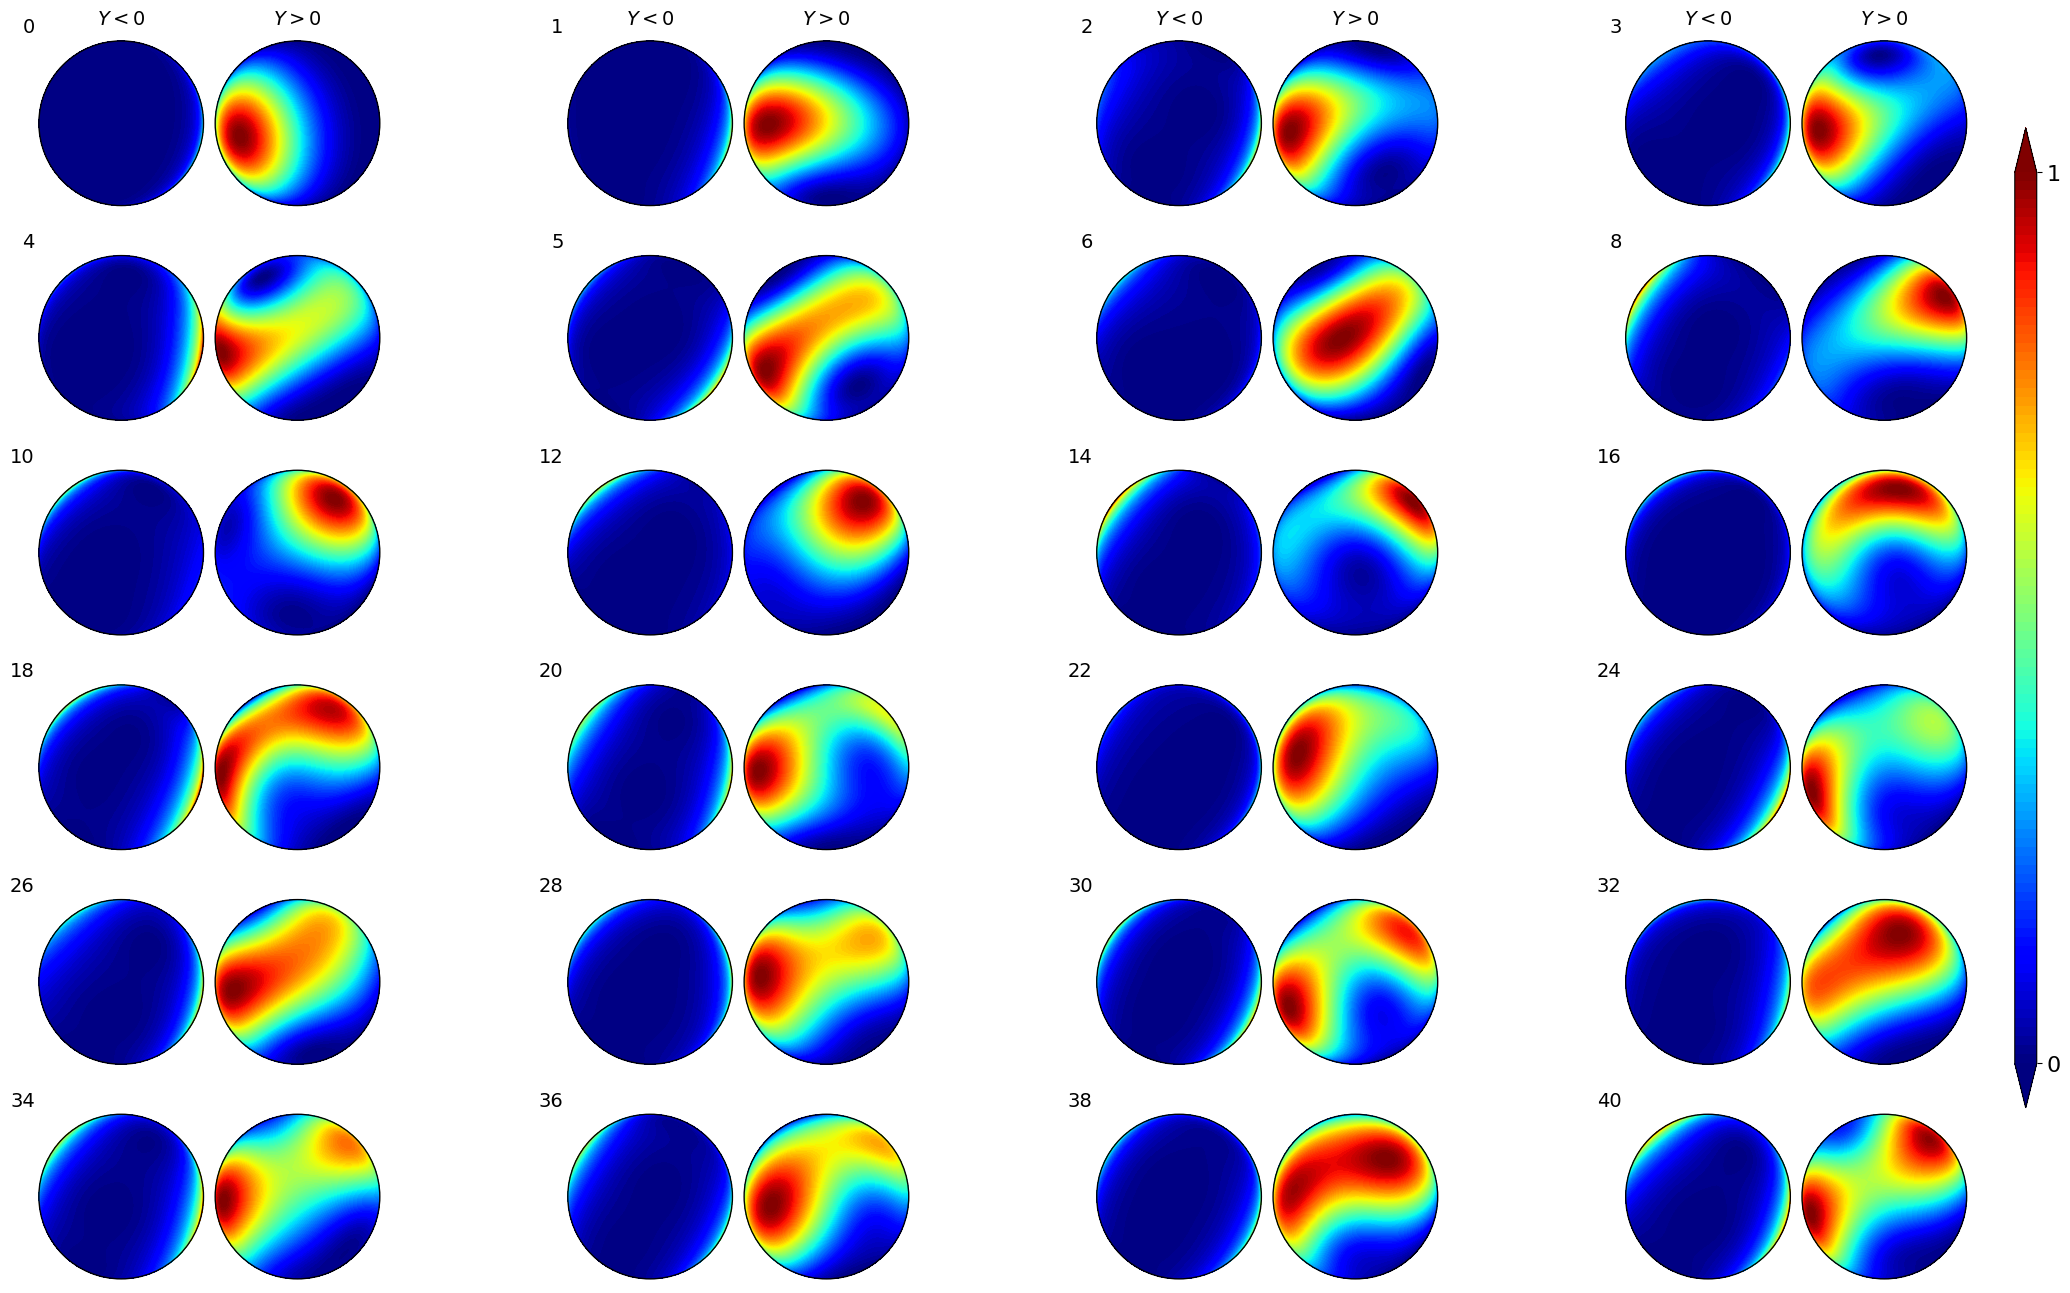

In [6]:
import numpy as np
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. SYSTEM PARAMETERS ---
j = 3
dim = int(2 * j + 1)
m = np.arange(j, -j - 1, -1)

# Spin matrices
Jz = np.diag(m).astype(complex)
Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim - 1):
    Jp[i, i + 1] = np.sqrt(j * (j + 1) - m[i + 1] * (m[i + 1] + 1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx

# Physics parameters
a_param = 0.4576
p_param = 0.99
k0 = 2.0
sigma_k = 0.05 * k0
Nk = 21
tau_param = 1.0
sigma_param = 0.001

USE_ODE_SOLVER = True  # Toggle for solve_ivp vs expm

# --- 2. FLOQUET OPERATOR CALCULATOR ---
def gaussian_pulse(t, tau_val, sigma_val):
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, k_val):
    U = U_flat.reshape((dim, dim))
    f_t = gaussian_pulse(t, tau_param, sigma_param)
    H_t = p_param * f_t * Jy + (k_val / (2.0 * j * tau_param)) * Jx_sq + (a_param / tau_param) * Jz
    return (-1j * (H_t @ U)).flatten()

def compute_floquet(k_val):
    if USE_ODE_SOLVER:
        U0 = np.eye(dim, dtype=complex).flatten()
        sol = solve_ivp(
            fun=ode_rhs,
            t_span=(0.0, tau_param),
            y0=U0,
            args=(k_val,),
            method='RK45',
            rtol=1e-10,
            atol=1e-12,
            max_step=sigma_param
        )
        return sol.y[:, -1].reshape((dim, dim))
    else:
        U_twist = expm(-1j * ((k_val * Jx_sq / (2 * j)) + a_param * Jz))
        U_kick = expm(-1j * p_param * Jy)
        return U_kick @ U_twist

# --- 3. FAST VECTORIZED COHERENT STATES ---
def get_single_coherent_state(theta_val, phi_val):
    state_0 = np.zeros((dim, 1), dtype=complex)
    state_0[0] = 1.0
    R = expm(-1j * phi_val * Jz) @ expm(-1j * theta_val * Jy)
    return R @ state_0

phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

state_0 = np.zeros((dim, 1), dtype=complex)
state_0[0] = 1.0

R_theta = np.zeros((len(theta), dim), dtype=complex)
for it, th in enumerate(theta):
    R_theta[it] = (expm(-1j * th * Jy) @ state_0).flatten()

exp_phi = np.exp(-1j * phi[:, None] * m[None, :])
coherent_grid = R_theta[:, None, :] * exp_phi[None, :, :]

# --- 4. K-AVERAGED DENSITY MATRIX PER KICK ---
vec = np.array([0.70, 0.70, -0.16]) # island pair
Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)
psi0 = get_single_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

n_list = np.arange(0, 41, 1)
num_kicks = len(n_list)

k_values = np.linspace(k0 - 3 * sigma_k, k0 + 3 * sigma_k, Nk)
weights = np.ones(Nk) / Nk

print(f"Accumulating k-averaged density matrices for {num_kicks} individual kicks...")

# Create an array to hold a separate density matrix for each kick
rho_per_kick = np.zeros((num_kicks, dim, dim), dtype=complex)

for weight, k_val in zip(weights, k_values):
    U = compute_floquet(k_val)
    eigvals, P = np.linalg.eig(U)
    P_inv = np.linalg.inv(P)
    psi_eigen = P_inv @ psi0

    # Evolve the state for this specific k and add it to the respective kick's matrix
    for n_idx, n in enumerate(n_list):
        psi_n = P @ ((eigvals**n)[:, None] * psi_eigen)
        rho_per_kick[n_idx] += weight * (psi_n @ psi_n.conj().T)

# --- 5. EVALUATE & PLOT SELECTED KICKS ---
print("Evaluating Husimi Q-function on 2D Grid...")

PHI, THETA = np.meshgrid(phi, theta)
X = np.sin(THETA) * np.cos(PHI)
Y = np.sin(THETA) * np.sin(PHI)
Z = np.cos(THETA)
levels = np.linspace(0, 1, 100)

# Exact sequence from the reference image "image_8e455a.png"
kicks_to_plot = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]

# INCREASED figsize for larger circles
fig = plt.figure(figsize=(22, 14))

for idx, n in enumerate(kicks_to_plot):
    # Determine the grid position for this pair
    row = idx // 4
    col_group = idx % 4

    # 11-column grid. Each pair takes 2 columns, followed by 1 empty column for spacing.
    col_left = col_group * 3
    col_right = col_left + 1

    ax_left = plt.subplot2grid((6, 11), (row, col_left))
    ax_right = plt.subplot2grid((6, 11), (row, col_right))

    # Calculate Husimi explicitly for this kick
    husimi_n = np.real(
        np.einsum('thd,de,the->th', coherent_grid.conj(), rho_per_kick[n], coherent_grid)
    )

    H = (husimi_n - husimi_n.min()) / (husimi_n.max() - husimi_n.min())
    H_pos = np.ma.masked_where(Y < 0, H)
    H_neg = np.ma.masked_where(Y > 0, H)

    # Plot Left Hemisphere (Y < 0)
    cont = ax_left.contourf(X, Z, H_neg, levels=levels, cmap='jet', extend='both')
    ax_left.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1))
    ax_left.set_aspect('equal')
    ax_left.set_xlim(-1.05, 1.05)
    ax_left.set_ylim(-1.05, 1.05)
    ax_left.axis("off")

    # Add kick number (n) to top left of the left hemisphere
    ax_left.text(-1.05, 1.05, str(n), fontsize=14, ha='right', va='bottom')

    # Plot Right Hemisphere (Y > 0)
    cont = ax_right.contourf(X, Z, H_pos, levels=levels, cmap='jet', extend='both')
    ax_right.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1))
    ax_right.set_aspect('equal')
    ax_right.set_xlim(-1.05, 1.05)
    ax_right.set_ylim(-1.05, 1.05)
    ax_right.invert_xaxis()
    ax_right.axis("off")

    # Add Y>0 / Y<0 labels ONLY on the first row
    if row == 0:
        ax_left.text(0, 1.2, r"$Y < 0$", ha='center', fontsize=14)
        ax_right.text(0, 1.2, r"$Y > 0$", ha='center', fontsize=14)

# OPTIMIZED margins: pulls plots closer to the edges and tightens vertical space
plt.subplots_adjust(left=0.02, right=0.9, top=0.92, bottom=0.02, wspace=0.02, hspace=0.15)

# Add a single colorbar spanning the right side
cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7]) # [left, bottom, width, height]
cbar = fig.colorbar(cont, cax=cbar_ax, ticks=[0, 1])
cbar.ax.set_yticklabels(['0', '1'])
cbar.ax.tick_params(labelsize=16)

plt.show()

Evolution of chaotic island

Accumulating k-averaged density matrices for 41 individual kicks...
Evaluating Husimi Q-function on 2D Grid...


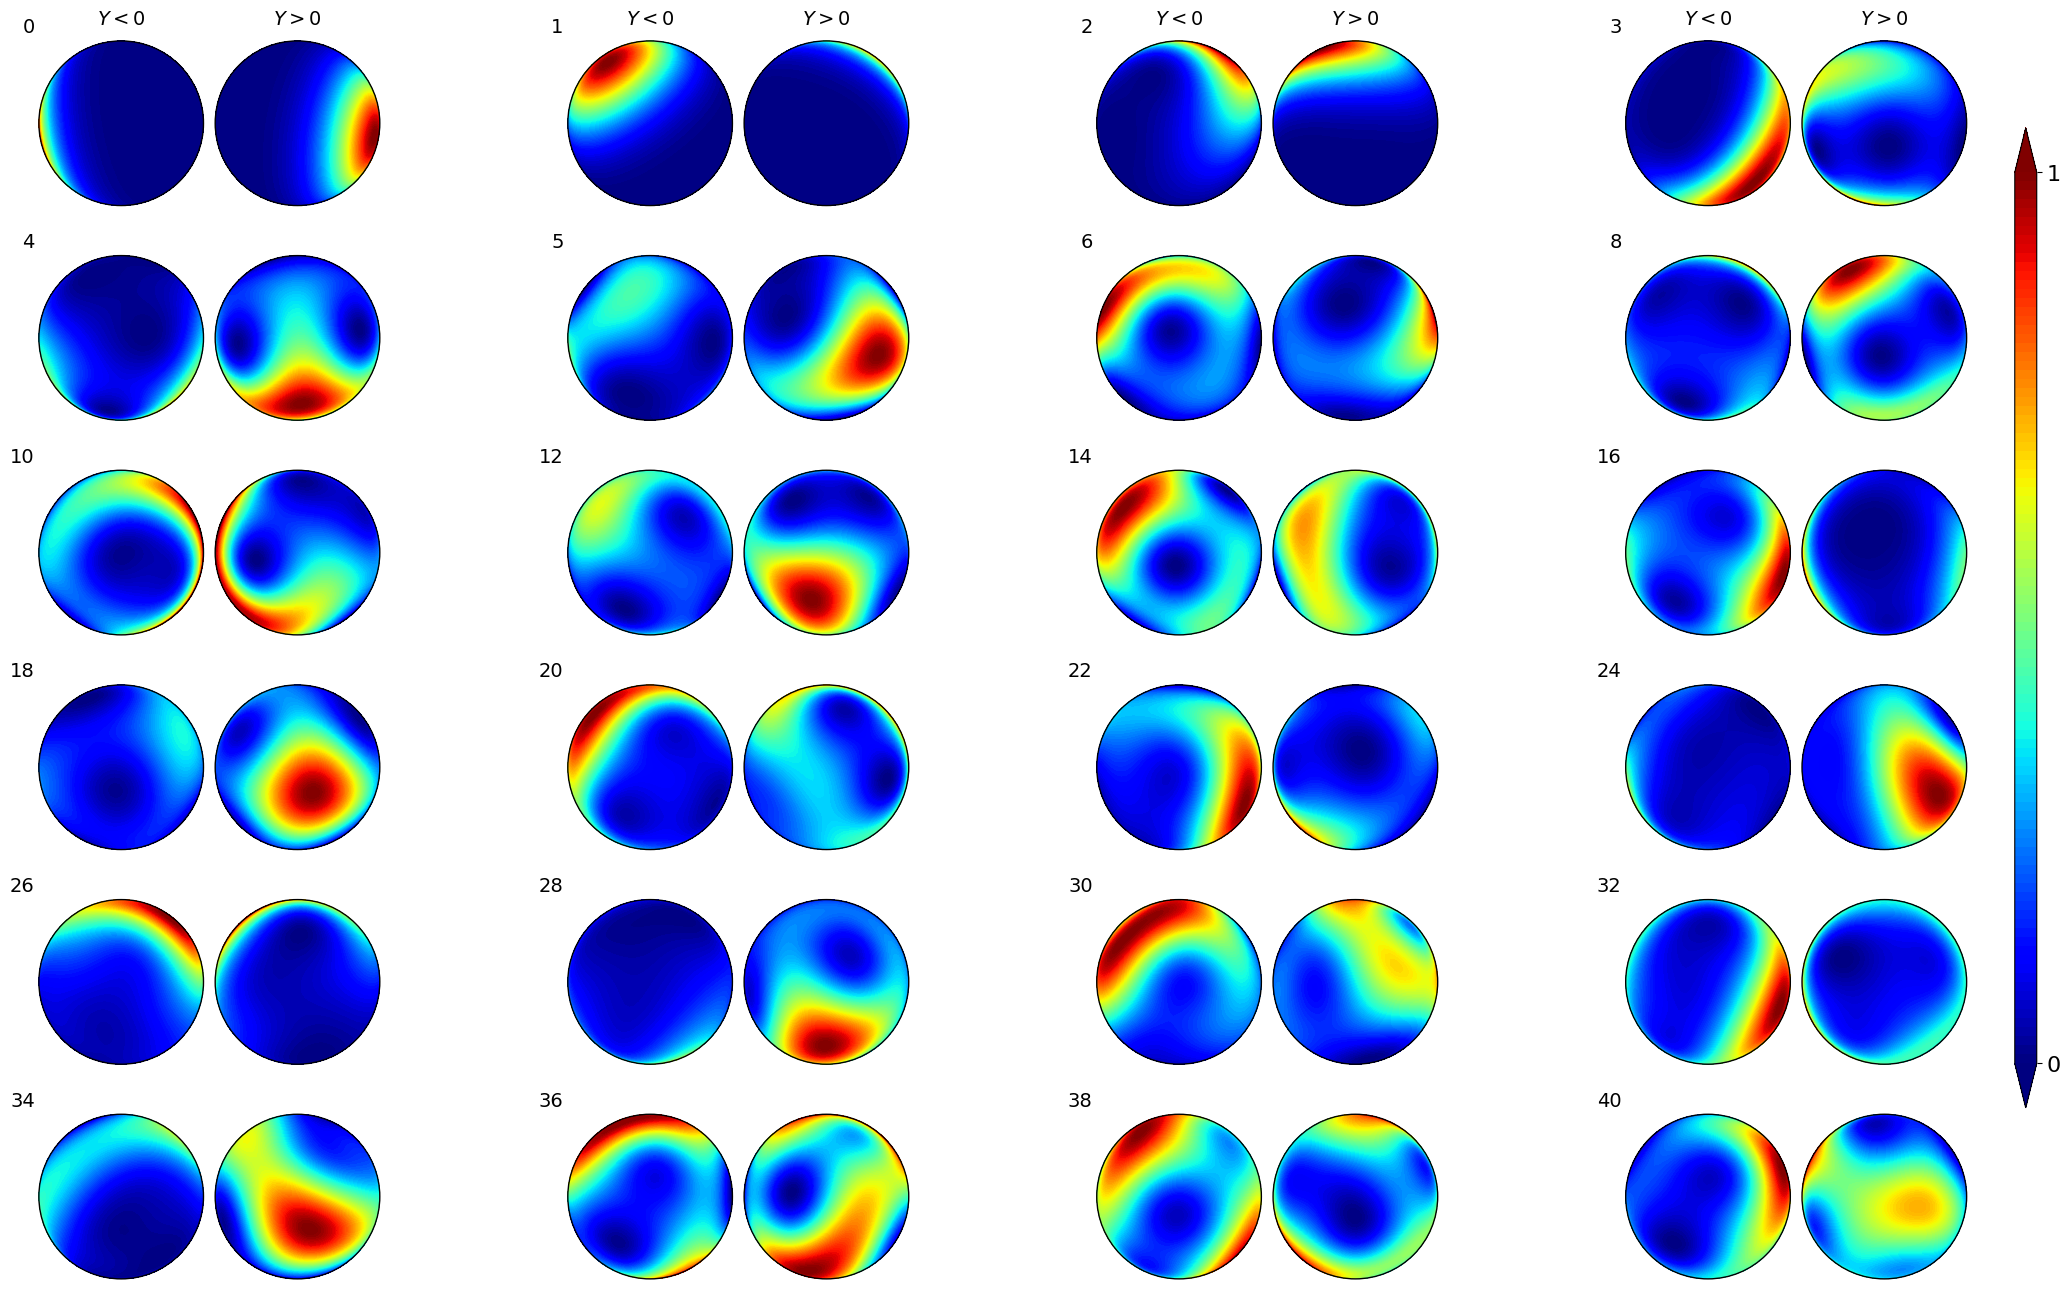

In [7]:
import numpy as np
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. SYSTEM PARAMETERS ---
j = 3
dim = int(2 * j + 1)
m = np.arange(j, -j - 1, -1)

# Spin matrices
Jz = np.diag(m).astype(complex)
Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim - 1):
    Jp[i, i + 1] = np.sqrt(j * (j + 1) - m[i + 1] * (m[i + 1] + 1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx

# Physics parameters
a_param = 0.4576
p_param = 0.99
k0 = 2.0
sigma_k = 0.05 * k0
Nk = 21
tau_param = 1.0
sigma_param = 0.001

USE_ODE_SOLVER = True  # Toggle for solve_ivp vs expm

# --- 2. FLOQUET OPERATOR CALCULATOR ---
def gaussian_pulse(t, tau_val, sigma_val):
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, k_val):
    U = U_flat.reshape((dim, dim))
    f_t = gaussian_pulse(t, tau_param, sigma_param)
    H_t = p_param * f_t * Jy + (k_val / (2.0 * j * tau_param)) * Jx_sq + (a_param / tau_param) * Jz
    return (-1j * (H_t @ U)).flatten()

def compute_floquet(k_val):
    if USE_ODE_SOLVER:
        U0 = np.eye(dim, dtype=complex).flatten()
        sol = solve_ivp(
            fun=ode_rhs,
            t_span=(0.0, tau_param),
            y0=U0,
            args=(k_val,),
            method='RK45',
            rtol=1e-10,
            atol=1e-12,
            max_step=sigma_param
        )
        return sol.y[:, -1].reshape((dim, dim))
    else:
        U_twist = expm(-1j * ((k_val * Jx_sq / (2 * j)) + a_param * Jz))
        U_kick = expm(-1j * p_param * Jy)
        return U_kick @ U_twist

# --- 3. FAST VECTORIZED COHERENT STATES ---
def get_single_coherent_state(theta_val, phi_val):
    state_0 = np.zeros((dim, 1), dtype=complex)
    state_0[0] = 1.0
    R = expm(-1j * phi_val * Jz) @ expm(-1j * theta_val * Jy)
    return R @ state_0

phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

state_0 = np.zeros((dim, 1), dtype=complex)
state_0[0] = 1.0

R_theta = np.zeros((len(theta), dim), dtype=complex)
for it, th in enumerate(theta):
    R_theta[it] = (expm(-1j * th * Jy) @ state_0).flatten()

exp_phi = np.exp(-1j * phi[:, None] * m[None, :])
coherent_grid = R_theta[:, None, :] * exp_phi[None, :, :]

# --- 4. K-AVERAGED DENSITY MATRIX PER KICK ---
vec = np.array([-0.94, 0.31, -0.16]) # island pair
Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)
psi0 = get_single_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

n_list = np.arange(0, 41, 1)
num_kicks = len(n_list)

k_values = np.linspace(k0 - 3 * sigma_k, k0 + 3 * sigma_k, Nk)
weights = np.ones(Nk) / Nk

print(f"Accumulating k-averaged density matrices for {num_kicks} individual kicks...")

# Create an array to hold a separate density matrix for each kick
rho_per_kick = np.zeros((num_kicks, dim, dim), dtype=complex)

for weight, k_val in zip(weights, k_values):
    U = compute_floquet(k_val)
    eigvals, P = np.linalg.eig(U)
    P_inv = np.linalg.inv(P)
    psi_eigen = P_inv @ psi0

    # Evolve the state for this specific k and add it to the respective kick's matrix
    for n_idx, n in enumerate(n_list):
        psi_n = P @ ((eigvals**n)[:, None] * psi_eigen)
        rho_per_kick[n_idx] += weight * (psi_n @ psi_n.conj().T)

# --- 5. EVALUATE & PLOT SELECTED KICKS ---
print("Evaluating Husimi Q-function on 2D Grid...")

PHI, THETA = np.meshgrid(phi, theta)
X = np.sin(THETA) * np.cos(PHI)
Y = np.sin(THETA) * np.sin(PHI)
Z = np.cos(THETA)
levels = np.linspace(0, 1, 100)

# Exact sequence from the reference image "image_8e455a.png"
kicks_to_plot = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]

# INCREASED figsize for larger circles
fig = plt.figure(figsize=(22, 14))

for idx, n in enumerate(kicks_to_plot):
    # Determine the grid position for this pair
    row = idx // 4
    col_group = idx % 4

    # 11-column grid. Each pair takes 2 columns, followed by 1 empty column for spacing.
    col_left = col_group * 3
    col_right = col_left + 1

    ax_left = plt.subplot2grid((6, 11), (row, col_left))
    ax_right = plt.subplot2grid((6, 11), (row, col_right))

    # Calculate Husimi explicitly for this kick
    husimi_n = np.real(
        np.einsum('thd,de,the->th', coherent_grid.conj(), rho_per_kick[n], coherent_grid)
    )

    H = (husimi_n - husimi_n.min()) / (husimi_n.max() - husimi_n.min())
    H_pos = np.ma.masked_where(Y < 0, H)
    H_neg = np.ma.masked_where(Y > 0, H)

    # Plot Left Hemisphere (Y < 0)
    cont = ax_left.contourf(X, Z, H_neg, levels=levels, cmap='jet', extend='both')
    ax_left.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1))
    ax_left.set_aspect('equal')
    ax_left.set_xlim(-1.05, 1.05)
    ax_left.set_ylim(-1.05, 1.05)
    ax_left.axis("off")

    # Add kick number (n) to top left of the left hemisphere
    ax_left.text(-1.05, 1.05, str(n), fontsize=14, ha='right', va='bottom')

    # Plot Right Hemisphere (Y > 0)
    cont = ax_right.contourf(X, Z, H_pos, levels=levels, cmap='jet', extend='both')
    ax_right.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1))
    ax_right.set_aspect('equal')
    ax_right.set_xlim(-1.05, 1.05)
    ax_right.set_ylim(-1.05, 1.05)
    ax_right.invert_xaxis()
    ax_right.axis("off")

    # Add Y>0 / Y<0 labels ONLY on the first row
    if row == 0:
        ax_left.text(0, 1.2, r"$Y < 0$", ha='center', fontsize=14)
        ax_right.text(0, 1.2, r"$Y > 0$", ha='center', fontsize=14)

# OPTIMIZED margins: pulls plots closer to the edges and tightens vertical space
plt.subplots_adjust(left=0.02, right=0.9, top=0.92, bottom=0.02, wspace=0.02, hspace=0.15)

# Add a single colorbar spanning the right side
cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7]) # [left, bottom, width, height]
cbar = fig.colorbar(cont, cax=cbar_ax, ticks=[0, 1])
cbar.ax.set_yticklabels(['0', '1'])
cbar.ax.tick_params(labelsize=16)

plt.show()

Evolution of Large island

Accumulating k-averaged density matrices for 41 individual kicks...
Evaluating Husimi Q-function on 2D Grid...


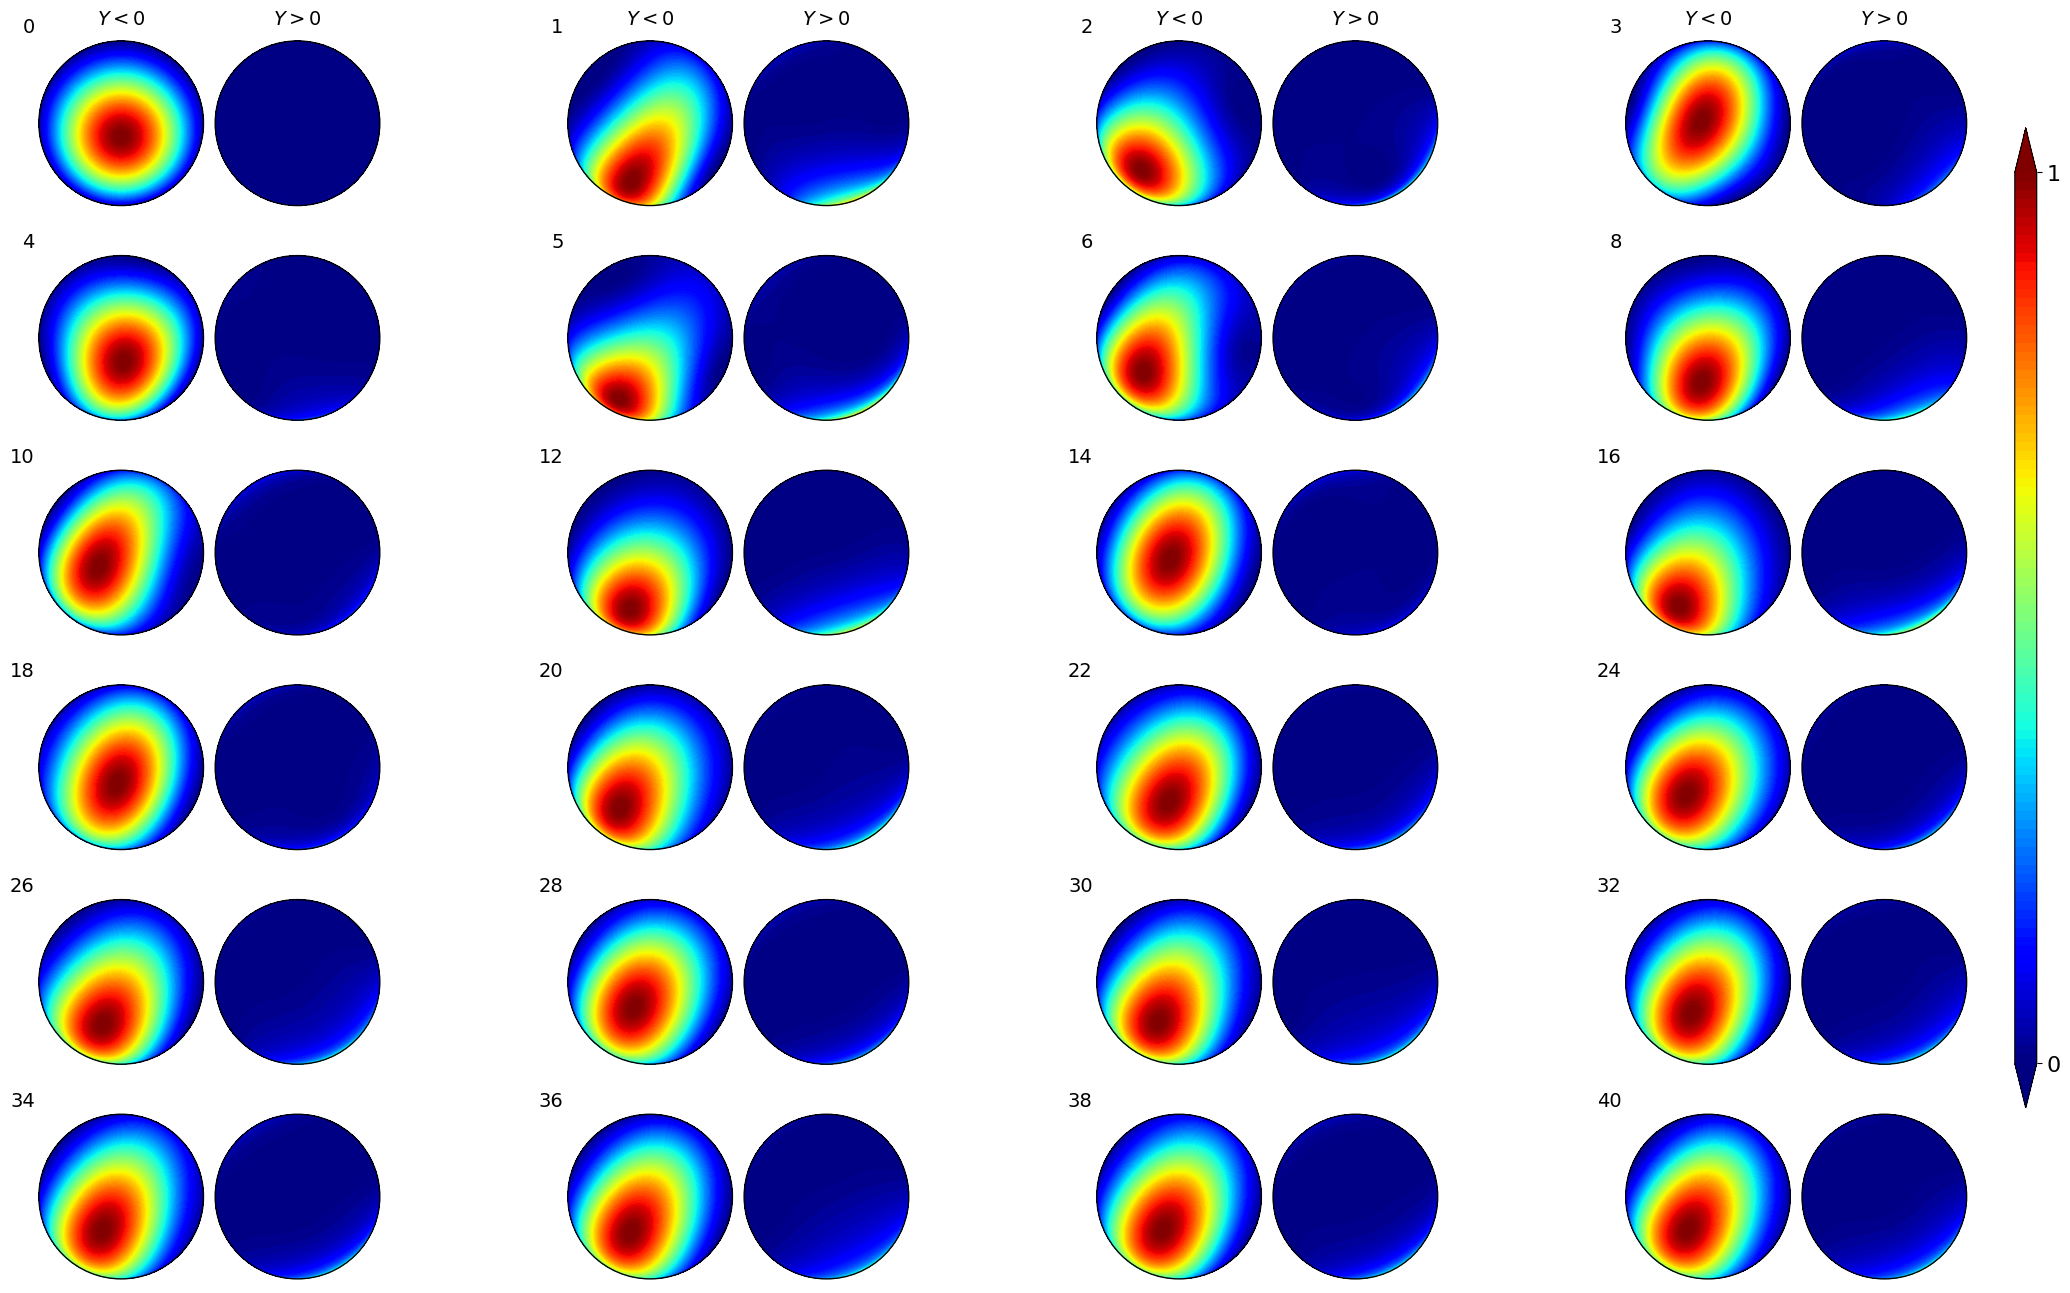

In [8]:
import numpy as np
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. SYSTEM PARAMETERS ---
j = 3
dim = int(2 * j + 1)
m = np.arange(j, -j - 1, -1)

# Spin matrices
Jz = np.diag(m).astype(complex)
Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim - 1):
    Jp[i, i + 1] = np.sqrt(j * (j + 1) - m[i + 1] * (m[i + 1] + 1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx

# Physics parameters
a_param = 0.4576
p_param = 0.99
k0 = 2.0
sigma_k = 0.05 * k0
Nk = 21
tau_param = 1.0
sigma_param = 0.001

USE_ODE_SOLVER = True  # Toggle for solve_ivp vs expm

# --- 2. FLOQUET OPERATOR CALCULATOR ---
def gaussian_pulse(t, tau_val, sigma_val):
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, k_val):
    U = U_flat.reshape((dim, dim))
    f_t = gaussian_pulse(t, tau_param, sigma_param)
    H_t = p_param * f_t * Jy + (k_val / (2.0 * j * tau_param)) * Jx_sq + (a_param / tau_param) * Jz
    return (-1j * (H_t @ U)).flatten()

def compute_floquet(k_val):
    if USE_ODE_SOLVER:
        U0 = np.eye(dim, dtype=complex).flatten()
        sol = solve_ivp(
            fun=ode_rhs,
            t_span=(0.0, tau_param),
            y0=U0,
            args=(k_val,),
            method='RK45',
            rtol=1e-10,
            atol=1e-12,
            max_step=sigma_param
        )
        return sol.y[:, -1].reshape((dim, dim))
    else:
        U_twist = expm(-1j * ((k_val * Jx_sq / (2 * j)) + a_param * Jz))
        U_kick = expm(-1j * p_param * Jy)
        return U_kick @ U_twist

# --- 3. FAST VECTORIZED COHERENT STATES ---
def get_single_coherent_state(theta_val, phi_val):
    state_0 = np.zeros((dim, 1), dtype=complex)
    state_0[0] = 1.0
    R = expm(-1j * phi_val * Jz) @ expm(-1j * theta_val * Jy)
    return R @ state_0

phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

state_0 = np.zeros((dim, 1), dtype=complex)
state_0[0] = 1.0

R_theta = np.zeros((len(theta), dim), dtype=complex)
for it, th in enumerate(theta):
    R_theta[it] = (expm(-1j * th * Jy) @ state_0).flatten()

exp_phi = np.exp(-1j * phi[:, None] * m[None, :])
coherent_grid = R_theta[:, None, :] * exp_phi[None, :, :]

# --- 4. K-AVERAGED DENSITY MATRIX PER KICK ---
vec = np.array([0.0, -0.99, -0.16]) # island pair
Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)
psi0 = get_single_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

n_list = np.arange(0, 41, 1)
num_kicks = len(n_list)

k_values = np.linspace(k0 - 3 * sigma_k, k0 + 3 * sigma_k, Nk)
weights = np.ones(Nk) / Nk

print(f"Accumulating k-averaged density matrices for {num_kicks} individual kicks...")

# Create an array to hold a separate density matrix for each kick
rho_per_kick = np.zeros((num_kicks, dim, dim), dtype=complex)

for weight, k_val in zip(weights, k_values):
    U = compute_floquet(k_val)
    eigvals, P = np.linalg.eig(U)
    P_inv = np.linalg.inv(P)
    psi_eigen = P_inv @ psi0

    # Evolve the state for this specific k and add it to the respective kick's matrix
    for n_idx, n in enumerate(n_list):
        psi_n = P @ ((eigvals**n)[:, None] * psi_eigen)
        rho_per_kick[n_idx] += weight * (psi_n @ psi_n.conj().T)

# --- 5. EVALUATE & PLOT SELECTED KICKS ---
print("Evaluating Husimi Q-function on 2D Grid...")

PHI, THETA = np.meshgrid(phi, theta)
X = np.sin(THETA) * np.cos(PHI)
Y = np.sin(THETA) * np.sin(PHI)
Z = np.cos(THETA)
levels = np.linspace(0, 1, 100)

# Exact sequence from the reference image "image_8e455a.png"
kicks_to_plot = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]

# INCREASED figsize for larger circles
fig = plt.figure(figsize=(22, 14))

for idx, n in enumerate(kicks_to_plot):
    # Determine the grid position for this pair
    row = idx // 4
    col_group = idx % 4

    # 11-column grid. Each pair takes 2 columns, followed by 1 empty column for spacing.
    col_left = col_group * 3
    col_right = col_left + 1

    ax_left = plt.subplot2grid((6, 11), (row, col_left))
    ax_right = plt.subplot2grid((6, 11), (row, col_right))

    # Calculate Husimi explicitly for this kick
    husimi_n = np.real(
        np.einsum('thd,de,the->th', coherent_grid.conj(), rho_per_kick[n], coherent_grid)
    )

    H = (husimi_n - husimi_n.min()) / (husimi_n.max() - husimi_n.min())
    H_pos = np.ma.masked_where(Y < 0, H)
    H_neg = np.ma.masked_where(Y > 0, H)

    # Plot Left Hemisphere (Y < 0)
    cont = ax_left.contourf(X, Z, H_neg, levels=levels, cmap='jet', extend='both')
    ax_left.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1))
    ax_left.set_aspect('equal')
    ax_left.set_xlim(-1.05, 1.05)
    ax_left.set_ylim(-1.05, 1.05)
    ax_left.axis("off")

    # Add kick number (n) to top left of the left hemisphere
    ax_left.text(-1.05, 1.05, str(n), fontsize=14, ha='right', va='bottom')

    # Plot Right Hemisphere (Y > 0)
    cont = ax_right.contourf(X, Z, H_pos, levels=levels, cmap='jet', extend='both')
    ax_right.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1))
    ax_right.set_aspect('equal')
    ax_right.set_xlim(-1.05, 1.05)
    ax_right.set_ylim(-1.05, 1.05)
    ax_right.invert_xaxis()
    ax_right.axis("off")

    # Add Y>0 / Y<0 labels ONLY on the first row
    if row == 0:
        ax_left.text(0, 1.2, r"$Y < 0$", ha='center', fontsize=14)
        ax_right.text(0, 1.2, r"$Y > 0$", ha='center', fontsize=14)

# OPTIMIZED margins: pulls plots closer to the edges and tightens vertical space
plt.subplots_adjust(left=0.02, right=0.9, top=0.92, bottom=0.02, wspace=0.02, hspace=0.15)

# Add a single colorbar spanning the right side
cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7]) # [left, bottom, width, height]
cbar = fig.colorbar(cont, cax=cbar_ax, ticks=[0, 1])
cbar.ax.set_yticklabels(['0', '1'])
cbar.ax.tick_params(labelsize=16)

plt.show()

>All the 3 fidelity plots are without k variation

Fidelity of Island Pair

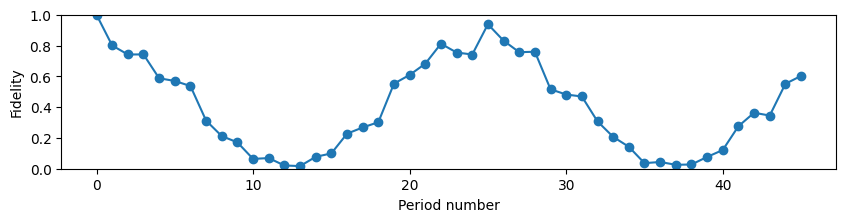

In [9]:
import numpy as np
from scipy.linalg import expm
import scipy.special as special
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. UNIFIED SYSTEM PARAMETERS ---
j = 3.0
dim = int(2 * j + 1)

# Using consistent physics parameters for both methods
a_param = 0.4576
p_param = 0.99
kappa_param = 2.0
tau_param = 1.0
sigma_param = 0.001

# --- 2. GENERATE SPIN MATRICES ONCE ---
m = np.arange(j, -j-1, -1)
Jz = np.diag(m).astype(complex)

Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim):
    for k in range(dim):
        if k == i+1:
            Jp[i, k] = np.sqrt(j*(j+1) - m[k]*(m[k]+1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx




def gaussian_pulse(t, tau_val, sigma_val):
    # Center the pulse 6*sigma before tau so the full integral falls exactly inside [0, tau]
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, Jx2, Jy_mat, Jz_mat, a, p, kappa, j_spin, tau, sigma):
    N = Jx2.shape[0]
    U = U_flat.reshape((N, N))

    f_t = gaussian_pulse(t, tau, sigma)

    # Time-dependent Hamiltonian
    H_t = p * f_t * Jy_mat + (kappa / (2.0 * j_spin * tau)) * Jx2 + (a / tau) * Jz_mat
    dU_dt = -1j * (H_t @ U)

    return dU_dt.flatten()

def compute_floquet_ode():
    U0 = np.eye(dim, dtype=complex).flatten()

    # CRITICAL FIX: max_step=sigma_param ensures the solver doesn't skip the kick
    sol = solve_ivp(
        fun=ode_rhs,
        t_span=(0.0, tau_param),
        y0=U0,
        args=(Jx_sq, Jy, Jz, a_param, p_param, kappa_param, j, tau_param, sigma_param),
        method='RK45',
        rtol=1e-10,
        atol=1e-12,
        max_step=sigma_param
    )

    return sol.y[:, -1].reshape((dim, dim))

U =  compute_floquet_ode()


eigenphases, P = np.linalg.eig(U)
D = np.diag(eigenphases)
P_inv = np.linalg.inv(P)

# def spin_coherent_state(theta, phi):
#     state = np.full((dim, 1), 1, dtype=complex)

#     z = np.tan(theta/2) * np.exp(-1j * phi)

#     for m in range(j, -j-1, -1):
#         coeff = (np.sqrt(special.factorial(int(2*j)) / (special.factorial(int(j+m)) * special.factorial(int(j-m)))))* (z**(j-m))
#         state[int(j-m)] = coeff

#     return state * (1+np.abs(z)**2)**(-j)

def spin_coherent_state(theta,phi):
    state = np.full((dim, 1), 0, dtype=complex)
    state[0] = 1
    R = expm(-1j * phi * Jz) @ expm(-1j * theta * Jy)

    return R @ state

# def spin_coherent_state(theta, phi):
#     # Precompute combinatorics: sqrt((2j)! / ((j+m)! (j-m)!)) using binomial coefficients
#     # 'k' goes from 0 to 2j, corresponding to (j - m)
#     k_vals = np.arange(0, int(2 * j + 1))
#     comb_coeffs = np.sqrt(special.comb(int(2 * j), k_vals))

#     # Calculate trig components (highly stable, no divisions, no tangents!)
#     cos_val = np.cos(theta / 2)
#     sin_val = np.sin(theta / 2)

#     # Vectorized calculation of all coefficients at once
#     coeffs = comb_coeffs * (sin_val ** k_vals) * (cos_val ** (int(2 * j) - k_vals)) * np.exp(1j * k_vals * phi)

#     return coeffs.reshape(-1, 1)

def Husimi_function(state, theta, phi):
    coherent_state = spin_coherent_state(theta, phi)
    return np.abs(np.vdot(coherent_state.flatten(), state.flatten()))**2


# def evolved_state(n,psi0):
#     return np.linalg.matrix_power(U, n) @ psi0

def evolved_state(n, psi0):
    # Transform psi0 to the eigenbasis
    psi_eigen = P_inv @ psi0

    # Apply the diagonal matrix D^n
    psi_eigen_n = np.diag(eigenphases**n) @ psi_eigen

    # Transform back to the original basis
    return P @ psi_eigen_n

vec = np.array([0.70, 0.70, -0.16])

Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)

n_list = np.arange(0,46,1)

psi0 = spin_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

psi_vals = []

for i in n_list:
    psi_n = evolved_state(i, psi0)
    psi_vals.append(psi_n.copy())


phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

husimi_store = []

psi = psi0.copy()

fidelity = []

for n in range(46):

    F = abs(np.vdot(psi0, psi))**2
    fidelity.append(F)

    psi = U @ psi

plt.figure(figsize=(10,2))

plt.plot(fidelity, '-o')

plt.xlabel("Period number")
plt.ylabel("Fidelity")

plt.ylim(0,1)

plt.show()

Fidelity of Chaotic sea

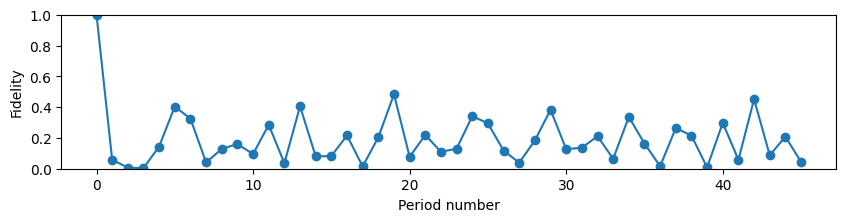

In [10]:
import numpy as np
from scipy.linalg import expm
import scipy.special as special
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. UNIFIED SYSTEM PARAMETERS ---
j = 3.0
dim = int(2 * j + 1)

# Using consistent physics parameters for both methods
a_param = 0.4576
p_param = 0.99
kappa_param = 2.0
tau_param = 1.0
sigma_param = 0.001

# --- 2. GENERATE SPIN MATRICES ONCE ---
m = np.arange(j, -j-1, -1)
Jz = np.diag(m).astype(complex)

Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim):
    for k in range(dim):
        if k == i+1:
            Jp[i, k] = np.sqrt(j*(j+1) - m[k]*(m[k]+1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx



def gaussian_pulse(t, tau_val, sigma_val):
    # Center the pulse 6*sigma before tau so the full integral falls exactly inside [0, tau]
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, Jx2, Jy_mat, Jz_mat, a, p, kappa, j_spin, tau, sigma):
    N = Jx2.shape[0]
    U = U_flat.reshape((N, N))

    f_t = gaussian_pulse(t, tau, sigma)

    # Time-dependent Hamiltonian
    H_t = p * f_t * Jy_mat + (kappa / (2.0 * j_spin * tau)) * Jx2 + (a / tau) * Jz_mat
    dU_dt = -1j * (H_t @ U)

    return dU_dt.flatten()

def compute_floquet_ode():
    U0 = np.eye(dim, dtype=complex).flatten()

    # CRITICAL FIX: max_step=sigma_param ensures the solver doesn't skip the kick
    sol = solve_ivp(
        fun=ode_rhs,
        t_span=(0.0, tau_param),
        y0=U0,
        args=(Jx_sq, Jy, Jz, a_param, p_param, kappa_param, j, tau_param, sigma_param),
        method='RK45',
        rtol=1e-10,
        atol=1e-12,
        max_step=sigma_param
    )

    return sol.y[:, -1].reshape((dim, dim))

U =  compute_floquet_ode()


eigenphases, P = np.linalg.eig(U)
D = np.diag(eigenphases)
P_inv = np.linalg.inv(P)

# def spin_coherent_state(theta, phi):
#     state = np.full((dim, 1), 1, dtype=complex)

#     z = np.tan(theta/2) * np.exp(-1j * phi)

#     for m in range(j, -j-1, -1):
#         coeff = (np.sqrt(special.factorial(int(2*j)) / (special.factorial(int(j+m)) * special.factorial(int(j-m)))))* (z**(j-m))
#         state[int(j-m)] = coeff

#     return state * (1+np.abs(z)**2)**(-j)

def spin_coherent_state(theta,phi):
    state = np.full((dim, 1), 0, dtype=complex)
    state[0] = 1
    R = expm(-1j * phi * Jz) @ expm(-1j * theta * Jy)

    return R @ state

# def spin_coherent_state(theta, phi):
#     # Precompute combinatorics: sqrt((2j)! / ((j+m)! (j-m)!)) using binomial coefficients
#     # 'k' goes from 0 to 2j, corresponding to (j - m)
#     k_vals = np.arange(0, int(2 * j + 1))
#     comb_coeffs = np.sqrt(special.comb(int(2 * j), k_vals))

#     # Calculate trig components (highly stable, no divisions, no tangents!)
#     cos_val = np.cos(theta / 2)
#     sin_val = np.sin(theta / 2)

#     # Vectorized calculation of all coefficients at once
#     coeffs = comb_coeffs * (sin_val ** k_vals) * (cos_val ** (int(2 * j) - k_vals)) * np.exp(1j * k_vals * phi)

#     return coeffs.reshape(-1, 1)

def Husimi_function(state, theta, phi):
    coherent_state = spin_coherent_state(theta, phi)
    return np.abs(np.vdot(coherent_state.flatten(), state.flatten()))**2


# def evolved_state(n,psi0):
#     return np.linalg.matrix_power(U, n) @ psi0

def evolved_state(n, psi0):
    # Transform psi0 to the eigenbasis
    psi_eigen = P_inv @ psi0

    # Apply the diagonal matrix D^n
    psi_eigen_n = np.diag(eigenphases**n) @ psi_eigen

    # Transform back to the original basis
    return P @ psi_eigen_n

vec = np.array([-0.94, 0.31, -0.16])


Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)

n_list = np.arange(0,46,1)

psi0 = spin_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

psi_vals = []

for i in n_list:
    psi_n = evolved_state(i, psi0)
    psi_vals.append(psi_n.copy())


phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

husimi_store = []

psi = psi0.copy()

fidelity = []

for n in range(46):

    F = abs(np.vdot(psi0, psi))**2
    fidelity.append(F)

    psi = U @ psi

plt.figure(figsize=(10,2))

plt.plot(fidelity, '-o')

plt.xlabel("Period number")
plt.ylabel("Fidelity")

plt.ylim(0,1)

plt.show()

Fidelity of large island

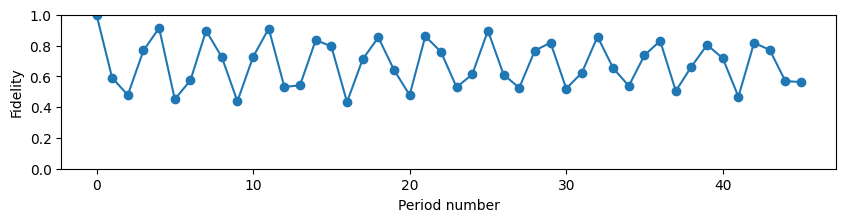

In [11]:
import numpy as np
from scipy.linalg import expm
import scipy.special as special
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. UNIFIED SYSTEM PARAMETERS ---
j = 3.0
dim = int(2 * j + 1)

# Using consistent physics parameters for both methods
a_param = 0.4576
p_param = 0.99
kappa_param = 2.0
tau_param = 1.0
sigma_param = 0.001

# --- 2. GENERATE SPIN MATRICES ONCE ---
m = np.arange(j, -j-1, -1)
Jz = np.diag(m).astype(complex)

Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim):
    for k in range(dim):
        if k == i+1:
            Jp[i, k] = np.sqrt(j*(j+1) - m[k]*(m[k]+1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx



def gaussian_pulse(t, tau_val, sigma_val):
    # Center the pulse 6*sigma before tau so the full integral falls exactly inside [0, tau]
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, Jx2, Jy_mat, Jz_mat, a, p, kappa, j_spin, tau, sigma):
    N = Jx2.shape[0]
    U = U_flat.reshape((N, N))

    f_t = gaussian_pulse(t, tau, sigma)

    # Time-dependent Hamiltonian
    H_t = p * f_t * Jy_mat + (kappa / (2.0 * j_spin * tau)) * Jx2 + (a / tau) * Jz_mat
    dU_dt = -1j * (H_t @ U)

    return dU_dt.flatten()

def compute_floquet_ode():
    U0 = np.eye(dim, dtype=complex).flatten()

    # CRITICAL FIX: max_step=sigma_param ensures the solver doesn't skip the kick
    sol = solve_ivp(
        fun=ode_rhs,
        t_span=(0.0, tau_param),
        y0=U0,
        args=(Jx_sq, Jy, Jz, a_param, p_param, kappa_param, j, tau_param, sigma_param),
        method='RK45',
        rtol=1e-10,
        atol=1e-12,
        max_step=sigma_param
    )

    return sol.y[:, -1].reshape((dim, dim))

U =  compute_floquet_ode()


eigenphases, P = np.linalg.eig(U)
D = np.diag(eigenphases)
P_inv = np.linalg.inv(P)

# def spin_coherent_state(theta, phi):
#     state = np.full((dim, 1), 1, dtype=complex)

#     z = np.tan(theta/2) * np.exp(-1j * phi)

#     for m in range(j, -j-1, -1):
#         coeff = (np.sqrt(special.factorial(int(2*j)) / (special.factorial(int(j+m)) * special.factorial(int(j-m)))))* (z**(j-m))
#         state[int(j-m)] = coeff

#     return state * (1+np.abs(z)**2)**(-j)

def spin_coherent_state(theta,phi):
    state = np.full((dim, 1), 0, dtype=complex)
    state[0] = 1
    R = expm(-1j * phi * Jz) @ expm(-1j * theta * Jy)

    return R @ state

# def spin_coherent_state(theta, phi):
#     # Precompute combinatorics: sqrt((2j)! / ((j+m)! (j-m)!)) using binomial coefficients
#     # 'k' goes from 0 to 2j, corresponding to (j - m)
#     k_vals = np.arange(0, int(2 * j + 1))
#     comb_coeffs = np.sqrt(special.comb(int(2 * j), k_vals))

#     # Calculate trig components (highly stable, no divisions, no tangents!)
#     cos_val = np.cos(theta / 2)
#     sin_val = np.sin(theta / 2)

#     # Vectorized calculation of all coefficients at once
#     coeffs = comb_coeffs * (sin_val ** k_vals) * (cos_val ** (int(2 * j) - k_vals)) * np.exp(1j * k_vals * phi)

#     return coeffs.reshape(-1, 1)

def Husimi_function(state, theta, phi):
    coherent_state = spin_coherent_state(theta, phi)
    return np.abs(np.vdot(coherent_state.flatten(), state.flatten()))**2


# def evolved_state(n,psi0):
#     return np.linalg.matrix_power(U, n) @ psi0

def evolved_state(n, psi0):
    # Transform psi0 to the eigenbasis
    psi_eigen = P_inv @ psi0

    # Apply the diagonal matrix D^n
    psi_eigen_n = np.diag(eigenphases**n) @ psi_eigen

    # Transform back to the original basis
    return P @ psi_eigen_n


vec = np.array([0, -0.99, -0.16])

Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)

n_list = np.arange(0,46,1)

psi0 = spin_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

psi_vals = []

for i in n_list:
    psi_n = evolved_state(i, psi0)
    psi_vals.append(psi_n.copy())


phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

husimi_store = []

psi = psi0.copy()

fidelity = []

for n in range(46):

    F = abs(np.vdot(psi0, psi))**2
    fidelity.append(F)

    psi = U @ psi

plt.figure(figsize=(10,2))

plt.plot(fidelity, '-o')

plt.xlabel("Period number")
plt.ylabel("Fidelity")
vec = np.array([-0.94, 0.31, -0.16])

plt.ylim(0,1)

plt.show()

Time averaged + K averaged Husimi plots for small regular island

Accumulating density matrix over 21 k-values and 41 kicks...
Evaluating Husimi Q-function on 2D Grid...


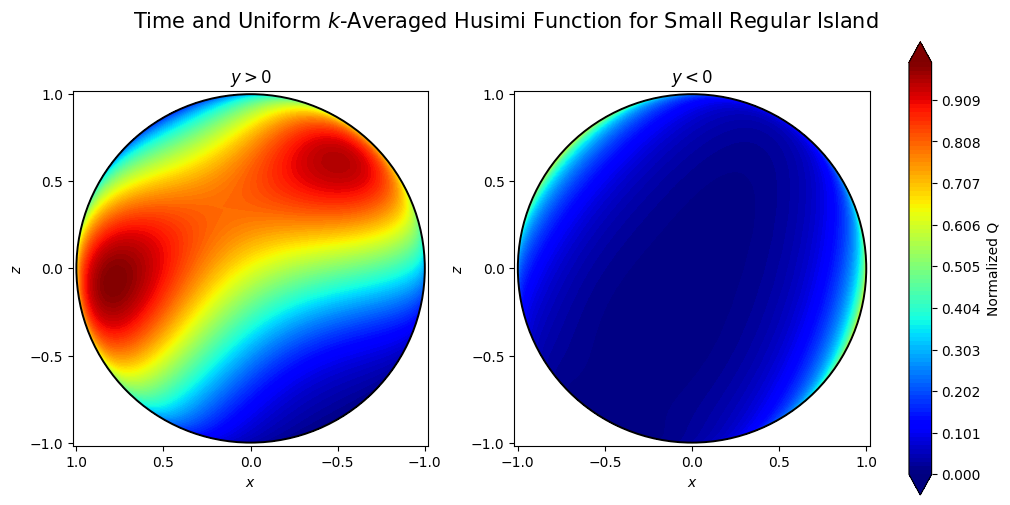

In [12]:
import numpy as np
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. SYSTEM PARAMETERS ---
j = 3
dim = int(2 * j + 1)
m = np.arange(j, -j - 1, -1)

# Spin matrices
Jz = np.diag(m).astype(complex)
Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim - 1):
    Jp[i, i + 1] = np.sqrt(j * (j + 1) - m[i + 1] * (m[i + 1] + 1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx

# Physics parameters
a_param = 0.4576
p_param = 0.99
k0 = 2.0
sigma_k = 0.05 * k0
Nk = 21
tau_param = 1.0
sigma_param = 0.001

USE_ODE_SOLVER = False  # Set to True if you want solve_ivp instead of expm

# --- 2. FLOQUET OPERATOR CALCULATOR ---
def gaussian_pulse(t, tau_val, sigma_val):
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, k_val):
    U = U_flat.reshape((dim, dim))
    f_t = gaussian_pulse(t, tau_param, sigma_param)
    H_t = p_param * f_t * Jy + (k_val / (2.0 * j * tau_param)) * Jx_sq + (a_param / tau_param) * Jz
    return (-1j * (H_t @ U)).flatten()

def compute_floquet(k_val):
    if USE_ODE_SOLVER:
        U0 = np.eye(dim, dtype=complex).flatten()
        sol = solve_ivp(
            fun=ode_rhs,
            t_span=(0.0, tau_param),
            y0=U0,
            args=(k_val,),
            method='RK45',
            rtol=1e-10,
            atol=1e-12,
            max_step=sigma_param
        )
        return sol.y[:, -1].reshape((dim, dim))
    else:
        # Exact delta-kick limit (thousands of times faster, identical for sigma=0.001)
        U_twist = expm(-1j * ((k_val * Jx_sq / (2 * j)) + a_param * Jz))
        U_kick = expm(-1j * p_param * Jy)
        return U_kick @ U_twist


# --- 3. FAST VECTORIZED COHERENT STATES ---
def get_single_coherent_state(theta, phi):
    state_0 = np.zeros((dim, 1), dtype=complex)
    state_0[0] = 1.0
    R = expm(-1j * phi * Jz) @ expm(-1j * theta * Jy)
    return R @ state_0

# Precompute 2D grid of coherent states in ~3ms
phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

state_0 = np.zeros((dim, 1), dtype=complex)
state_0[0] = 1.0

# 100 theta rotations instead of 10,000 full matrix exponentials
R_theta = np.zeros((len(theta), dim), dtype=complex)
for it, th in enumerate(theta):
    R_theta[it] = (expm(-1j * th * Jy) @ state_0).flatten()

# Elementwise diagonal phi phase multiplication
exp_phi = np.exp(-1j * phi[:, None] * m[None, :])  # Shape: (100, dim)
coherent_grid = R_theta[:, None, :] * exp_phi[None, :, :]  # Shape: (100, 100, dim)


# --- 4. TIME & K-AVERAGED DENSITY MATRIX ACCUMULATION ---
vec = np.array([0.70, 0.70, -0.16]) #island pair
# vec = np.array([-0.94, 0.31, -0.16]) #chaotic sea
# vec = np.array([0, -0.99, -0.16]) #large island
Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)
psi0 = get_single_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

n_list = np.arange(0, 41, 1)
num_kicks = len(n_list)

k_values = np.linspace(k0 - 3 * sigma_k, k0 + 3 * sigma_k, Nk)
weights = np.ones(Nk) / Nk

print(f"Accumulating density matrix over {Nk} k-values and {num_kicks} kicks...")

rho_total = np.zeros((dim, dim), dtype=complex)

for weight, k_val in zip(weights, k_values):
    U = compute_floquet(k_val)
    eigvals, P = np.linalg.eig(U)
    P_inv = np.linalg.inv(P)
    psi_eigen = P_inv @ psi0

    # Accumulate density matrix for this k
    rho_k = np.zeros((dim, dim), dtype=complex)
    for n in n_list:
        psi_n = P @ ((eigvals**n)[:, None] * psi_eigen)
        rho_k += (psi_n @ psi_n.conj().T) / num_kicks

    rho_total += weight * rho_k


# --- 5. SINGLE-PASS HUSIMI EVALUATION ---
print("Evaluating Husimi Q-function on 2D Grid...")
# Computes <c|rho|c> for all 10,000 grid points simultaneously using einsum
husimi_averaged = np.real(
    np.einsum('thd,de,the->th', coherent_grid.conj(), rho_total, coherent_grid)
)


# --- 6. PLOTTING ---
PHI, THETA = np.meshgrid(phi, theta)
X = np.sin(THETA) * np.cos(PHI)
Y = np.sin(THETA) * np.sin(PHI)
Z = np.cos(THETA)

levels = np.linspace(0, 1, 100)
titles = [r'$y>0$', r'$y<0$']

Hraw = husimi_averaged
H = (Hraw - Hraw.min()) / (Hraw.max() - Hraw.min())

H_pos = np.ma.masked_where(Y < 0, H)
H_neg = np.ma.masked_where(Y > 0, H)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, data, title in zip(axes, [H_pos, H_neg], titles):
    cont = ax.contourf(X, Z, data, levels=levels, cmap='jet', extend='both')
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1.4))
    ax.set_aspect('equal')
    ax.set_xlim(-1.02, 1.02)
    ax.set_ylim(-1.02, 1.02)
    ax.set_xticks([-1, -0.5, 0, 0.5, 1])
    ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$z$')
    ax.set_title(title)

axes[0].invert_xaxis()
cbar = fig.colorbar(cont, ax=axes, fraction=0.045, pad=0.04)
cbar.set_label("Normalized Q")

fig.suptitle(r'Time and Uniform $k$-Averaged Husimi Function for Small Regular Island', fontsize=15)
plt.show()

Time averaged + K averaged Husimi plots for large regular island

Accumulating density matrix over 21 k-values and 41 kicks...
Evaluating Husimi Q-function on 2D Grid...


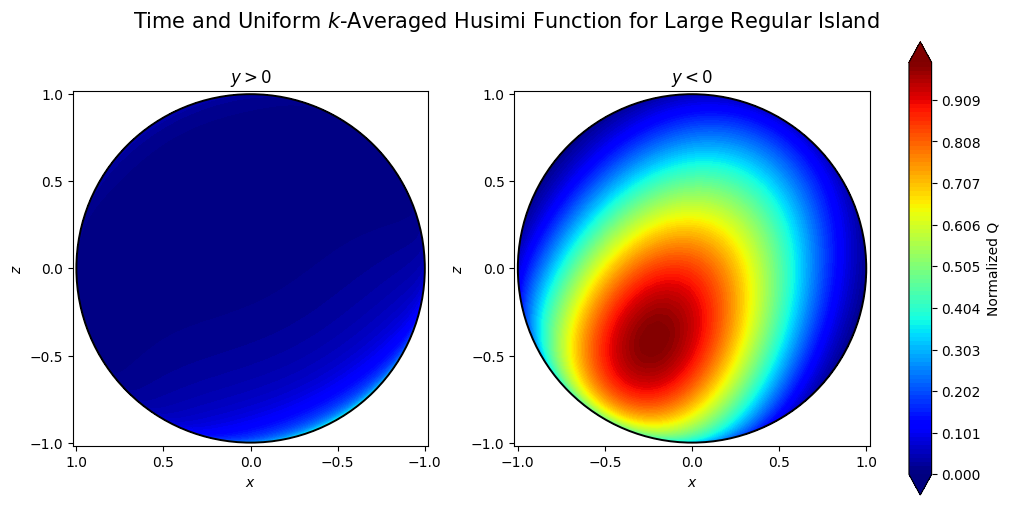

In [13]:
import numpy as np
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. SYSTEM PARAMETERS ---
j = 3
dim = int(2 * j + 1)
m = np.arange(j, -j - 1, -1)

# Spin matrices
Jz = np.diag(m).astype(complex)
Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim - 1):
    Jp[i, i + 1] = np.sqrt(j * (j + 1) - m[i + 1] * (m[i + 1] + 1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx

# Physics parameters
a_param = 0.4576
p_param = 0.99
k0 = 2.0
sigma_k = 0.05 * k0
Nk = 21
tau_param = 1.0
sigma_param = 0.001

USE_ODE_SOLVER = False  # Set to True if you want solve_ivp instead of expm

# --- 2. FLOQUET OPERATOR CALCULATOR ---
def gaussian_pulse(t, tau_val, sigma_val):
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, k_val):
    U = U_flat.reshape((dim, dim))
    f_t = gaussian_pulse(t, tau_param, sigma_param)
    H_t = p_param * f_t * Jy + (k_val / (2.0 * j * tau_param)) * Jx_sq + (a_param / tau_param) * Jz
    return (-1j * (H_t @ U)).flatten()

def compute_floquet(k_val):
    if USE_ODE_SOLVER:
        U0 = np.eye(dim, dtype=complex).flatten()
        sol = solve_ivp(
            fun=ode_rhs,
            t_span=(0.0, tau_param),
            y0=U0,
            args=(k_val,),
            method='RK45',
            rtol=1e-10,
            atol=1e-12,
            max_step=sigma_param
        )
        return sol.y[:, -1].reshape((dim, dim))
    else:
        # Exact delta-kick limit (thousands of times faster, identical for sigma=0.001)
        U_twist = expm(-1j * ((k_val * Jx_sq / (2 * j)) + a_param * Jz))
        U_kick = expm(-1j * p_param * Jy)
        return U_kick @ U_twist


# --- 3. FAST VECTORIZED COHERENT STATES ---
def get_single_coherent_state(theta, phi):
    state_0 = np.zeros((dim, 1), dtype=complex)
    state_0[0] = 1.0
    R = expm(-1j * phi * Jz) @ expm(-1j * theta * Jy)
    return R @ state_0

# Precompute 2D grid of coherent states in ~3ms
phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

state_0 = np.zeros((dim, 1), dtype=complex)
state_0[0] = 1.0

# 100 theta rotations instead of 10,000 full matrix exponentials
R_theta = np.zeros((len(theta), dim), dtype=complex)
for it, th in enumerate(theta):
    R_theta[it] = (expm(-1j * th * Jy) @ state_0).flatten()

# Elementwise diagonal phi phase multiplication
exp_phi = np.exp(-1j * phi[:, None] * m[None, :])  # Shape: (100, dim)
coherent_grid = R_theta[:, None, :] * exp_phi[None, :, :]  # Shape: (100, 100, dim)


# --- 4. TIME & K-AVERAGED DENSITY MATRIX ACCUMULATION ---
# vec = np.array([0.70, 0.70, -0.16]) #island pair
# vec = np.array([-0.94, 0.31, -0.16]) #chaotic sea
vec = np.array([0, -0.99, -0.16]) #large island
Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)
psi0 = get_single_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

n_list = np.arange(0, 41, 1)
num_kicks = len(n_list)

k_values = np.linspace(k0 - 3 * sigma_k, k0 + 3 * sigma_k, Nk)
weights = np.ones(Nk) / Nk

print(f"Accumulating density matrix over {Nk} k-values and {num_kicks} kicks...")

rho_total = np.zeros((dim, dim), dtype=complex)

for weight, k_val in zip(weights, k_values):
    U = compute_floquet(k_val)
    eigvals, P = np.linalg.eig(U)
    P_inv = np.linalg.inv(P)
    psi_eigen = P_inv @ psi0

    # Accumulate density matrix for this k
    rho_k = np.zeros((dim, dim), dtype=complex)
    for n in n_list:
        psi_n = P @ ((eigvals**n)[:, None] * psi_eigen)
        rho_k += (psi_n @ psi_n.conj().T) / num_kicks

    rho_total += weight * rho_k


# --- 5. SINGLE-PASS HUSIMI EVALUATION ---
print("Evaluating Husimi Q-function on 2D Grid...")
# Computes <c|rho|c> for all 10,000 grid points simultaneously using einsum
husimi_averaged = np.real(
    np.einsum('thd,de,the->th', coherent_grid.conj(), rho_total, coherent_grid)
)


# --- 6. PLOTTING ---
PHI, THETA = np.meshgrid(phi, theta)
X = np.sin(THETA) * np.cos(PHI)
Y = np.sin(THETA) * np.sin(PHI)
Z = np.cos(THETA)

levels = np.linspace(0, 1, 100)
titles = [r'$y>0$', r'$y<0$']

Hraw = husimi_averaged
H = (Hraw - Hraw.min()) / (Hraw.max() - Hraw.min())

H_pos = np.ma.masked_where(Y < 0, H)
H_neg = np.ma.masked_where(Y > 0, H)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, data, title in zip(axes, [H_pos, H_neg], titles):
    cont = ax.contourf(X, Z, data, levels=levels, cmap='jet', extend='both')
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1.4))
    ax.set_aspect('equal')
    ax.set_xlim(-1.02, 1.02)
    ax.set_ylim(-1.02, 1.02)
    ax.set_xticks([-1, -0.5, 0, 0.5, 1])
    ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$z$')
    ax.set_title(title)

axes[0].invert_xaxis()
cbar = fig.colorbar(cont, ax=axes, fraction=0.045, pad=0.04)
cbar.set_label("Normalized Q")

fig.suptitle(r'Time and Uniform $k$-Averaged Husimi Function for Large Regular Island', fontsize=15)
plt.show()

Time averaged + K averaged Husimi plots for chaotic sea

Accumulating density matrix over 21 k-values and 41 kicks...
Evaluating Husimi Q-function on 2D Grid...


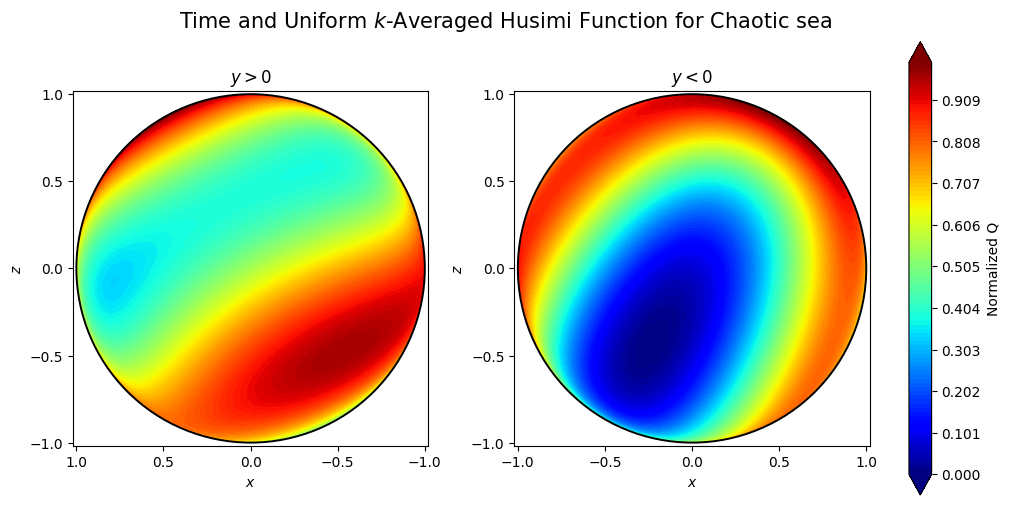

In [1]:
import numpy as np
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- 1. SYSTEM PARAMETERS ---
j = 3
dim = int(2 * j + 1)
m = np.arange(j, -j - 1, -1)

# Spin matrices
Jz = np.diag(m).astype(complex)
Jp = np.zeros((dim, dim), dtype=complex)
for i in range(dim - 1):
    Jp[i, i + 1] = np.sqrt(j * (j + 1) - m[i + 1] * (m[i + 1] + 1))

Jm = np.conj(Jp.T)
Jx = (Jp + Jm) / 2.0
Jy = (Jp - Jm) / 2j
Jx_sq = Jx @ Jx

# Physics parameters
a_param = 0.4576
p_param = 0.99
k0 = 2.0
sigma_k = 0.05 * k0
Nk = 21
tau_param = 1.0
sigma_param = 0.001

USE_ODE_SOLVER = False  # Set to True if you want solve_ivp instead of expm

# --- 2. FLOQUET OPERATOR CALCULATOR ---
def gaussian_pulse(t, tau_val, sigma_val):
    t_center = tau_val - 6.0 * sigma_val
    return (1.0 / (sigma_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - t_center) / sigma_val)**2)

def ode_rhs(t, U_flat, k_val):
    U = U_flat.reshape((dim, dim))
    f_t = gaussian_pulse(t, tau_param, sigma_param)
    H_t = p_param * f_t * Jy + (k_val / (2.0 * j * tau_param)) * Jx_sq + (a_param / tau_param) * Jz
    return (-1j * (H_t @ U)).flatten()

def compute_floquet(k_val):
    if USE_ODE_SOLVER:
        U0 = np.eye(dim, dtype=complex).flatten()
        sol = solve_ivp(
            fun=ode_rhs,
            t_span=(0.0, tau_param),
            y0=U0,
            args=(k_val,),
            method='RK45',
            rtol=1e-10,
            atol=1e-12,
            max_step=sigma_param
        )
        return sol.y[:, -1].reshape((dim, dim))
    else:
        # Exact delta-kick limit (thousands of times faster, identical for sigma=0.001)
        U_twist = expm(-1j * ((k_val * Jx_sq / (2 * j)) + a_param * Jz))
        U_kick = expm(-1j * p_param * Jy)
        return U_kick @ U_twist


# --- 3. FAST VECTORIZED COHERENT STATES ---
def get_single_coherent_state(theta, phi):
    state_0 = np.zeros((dim, 1), dtype=complex)
    state_0[0] = 1.0
    R = expm(-1j * phi * Jz) @ expm(-1j * theta * Jy)
    return R @ state_0

# Precompute 2D grid of coherent states in ~3ms
phi = np.linspace(0, 2 * np.pi, 100)
theta = np.linspace(0, np.pi, 100)

state_0 = np.zeros((dim, 1), dtype=complex)
state_0[0] = 1.0

# 100 theta rotations instead of 10,000 full matrix exponentials
R_theta = np.zeros((len(theta), dim), dtype=complex)
for it, th in enumerate(theta):
    R_theta[it] = (expm(-1j * th * Jy) @ state_0).flatten()

# Elementwise diagonal phi phase multiplication
exp_phi = np.exp(-1j * phi[:, None] * m[None, :])  # Shape: (100, dim)
coherent_grid = R_theta[:, None, :] * exp_phi[None, :, :]  # Shape: (100, 100, dim)


# --- 4. TIME & K-AVERAGED DENSITY MATRIX ACCUMULATION ---
# vec = np.array([0.70, 0.70, -0.16]) #island pair
vec = np.array([-0.94, 0.31, -0.16]) #chaotic sea
# vec = np.array([0, -0.99, -0.16]) #large island
Jx0, Jy0, Jz0 = vec / np.linalg.norm(vec)
psi0 = get_single_coherent_state(np.arccos(Jz0), np.arctan2(Jy0, Jx0))

n_list = np.arange(0, 41, 1)
num_kicks = len(n_list)

k_values = np.linspace(k0 - 3 * sigma_k, k0 + 3 * sigma_k, Nk)
weights = np.ones(Nk) / Nk

print(f"Accumulating density matrix over {Nk} k-values and {num_kicks} kicks...")

rho_total = np.zeros((dim, dim), dtype=complex)

for weight, k_val in zip(weights, k_values):
    U = compute_floquet(k_val)
    eigvals, P = np.linalg.eig(U)
    P_inv = np.linalg.inv(P)
    psi_eigen = P_inv @ psi0

    # Accumulate density matrix for this k
    rho_k = np.zeros((dim, dim), dtype=complex)
    for n in n_list:
        psi_n = P @ ((eigvals**n)[:, None] * psi_eigen)
        rho_k += (psi_n @ psi_n.conj().T) / num_kicks

    rho_total += weight * rho_k


# --- 5. SINGLE-PASS HUSIMI EVALUATION ---
print("Evaluating Husimi Q-function on 2D Grid...")
# Computes <c|rho|c> for all 10,000 grid points simultaneously using einsum
husimi_averaged = np.real(
    np.einsum('thd,de,the->th', coherent_grid.conj(), rho_total, coherent_grid)
)


# --- 6. PLOTTING ---
PHI, THETA = np.meshgrid(phi, theta)
X = np.sin(THETA) * np.cos(PHI)
Y = np.sin(THETA) * np.sin(PHI)
Z = np.cos(THETA)

levels = np.linspace(0, 1, 100)
titles = [r'$y>0$', r'$y<0$']

Hraw = husimi_averaged
H = (Hraw - Hraw.min()) / (Hraw.max() - Hraw.min())

H_pos = np.ma.masked_where(Y < 0, H)
H_neg = np.ma.masked_where(Y > 0, H)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, data, title in zip(axes, [H_pos, H_neg], titles):
    cont = ax.contourf(X, Z, data, levels=levels, cmap='jet', extend='both')
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='black', lw=1.4))
    ax.set_aspect('equal')
    ax.set_xlim(-1.02, 1.02)
    ax.set_ylim(-1.02, 1.02)
    ax.set_xticks([-1, -0.5, 0, 0.5, 1])
    ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$z$')
    ax.set_title(title)

axes[0].invert_xaxis()
cbar = fig.colorbar(cont, ax=axes, fraction=0.045, pad=0.04)
cbar.set_label("Normalized Q")

fig.suptitle(r'Time and Uniform $k$-Averaged Husimi Function for Chaotic sea', fontsize=15)
plt.show()